In [12]:
# Notebook-wide plot styling: serif font and light gray backgrounds
import matplotlib as mpl
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "axes.edgecolor": "#c8c8c8",
    "axes.linewidth": 1.0,
    "axes.facecolor": "#f2f2f2",
    "figure.facecolor": "#f7f7f7",
    "grid.color": "#d9d9d9",
    "grid.alpha": 1.0,
    "grid.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "legend.frameon": False,
})
print("Plot styling applied: serif font + light gray backgrounds")

Plot styling applied: serif font + light gray backgrounds


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1) Load exported long-format data

def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "1. data").exists() and (p / "2. code").exists():
            return p
    return start

project_root = find_project_root(Path.cwd())
output_dir = project_root / "1. data" / "output_data"

csv_2 = output_dir / "equilibrium_2state_arg_all_results_long.csv"
csv_4 = output_dir / "equilibrium_4state_arg_all_results_long.csv"

if not csv_2.exists() or not csv_4.exists():
    raise FileNotFoundError(
        "Missing exports. Please confirm both files exist:\n"
        f" - {csv_2}\n"
        f" - {csv_4}"
    )

long_2 = pd.read_csv(csv_2, low_memory=False)
long_4 = pd.read_csv(csv_4, low_memory=False)

# Force numeric types for robust aggregation in later cells.
for df in (long_2, long_4):
    df["eta"] = pd.to_numeric(df["eta"], errors="coerce")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")

print("Loaded:")
print(f"2-state -> {csv_2}")
print(f"4-state -> {csv_4}")
print(f"Rows: 2-state={len(long_2):,}, 4-state={len(long_4):,}")

# 2) Helper to extract one section from table outputs
metrics_keep = ["r*", "Mean(a)", "Borrowers Mass", "Mass Informal", "Mass Formal"]
section_to_source = {"4.1": "df_41", "4.4": "df_44"}

def extract_section(df_long: pd.DataFrame, section_label: str, model_name: str) -> pd.DataFrame:
    source_name = section_to_source[section_label]
    t = df_long[
        (df_long["data_kind"] == "table")
        & (df_long["source"] == source_name)
        & (df_long["scenario"].isin(metrics_keep))
    ].copy()

    if t.empty:
        return pd.DataFrame(columns=["model", "section", "eta", "metric", "value"])

    t = (
        t.groupby(["eta", "scenario"], as_index=False)["value"]
        .mean()
        .rename(columns={"scenario": "metric"})
    )
    t["model"] = model_name
    t["section"] = section_label
    return t[["model", "section", "eta", "metric", "value"]]

Loaded:
2-state -> c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\equilibrium_2state_arg_all_results_long.csv
4-state -> c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\equilibrium_4state_arg_all_results_long.csv
Rows: 2-state=67,738, 4-state=163,960


Section 4.4 comparison table (sample):
  model section  eta         metric    value
2-state     4.4 0.20 Borrowers Mass 0.377621
4-state     4.4 0.20 Borrowers Mass 0.481870
2-state     4.4 0.42 Borrowers Mass 0.494752
4-state     4.4 0.42 Borrowers Mass 0.449436
2-state     4.4 0.20    Mass Formal 0.800000
4-state     4.4 0.20    Mass Formal 0.800000
2-state     4.4 0.42    Mass Formal 0.580000
4-state     4.4 0.42    Mass Formal 0.580000
2-state     4.4 0.20  Mass Informal 0.200000
4-state     4.4 0.20  Mass Informal 0.200000
2-state     4.4 0.42  Mass Informal 0.420000
4-state     4.4 0.42  Mass Informal 0.420000


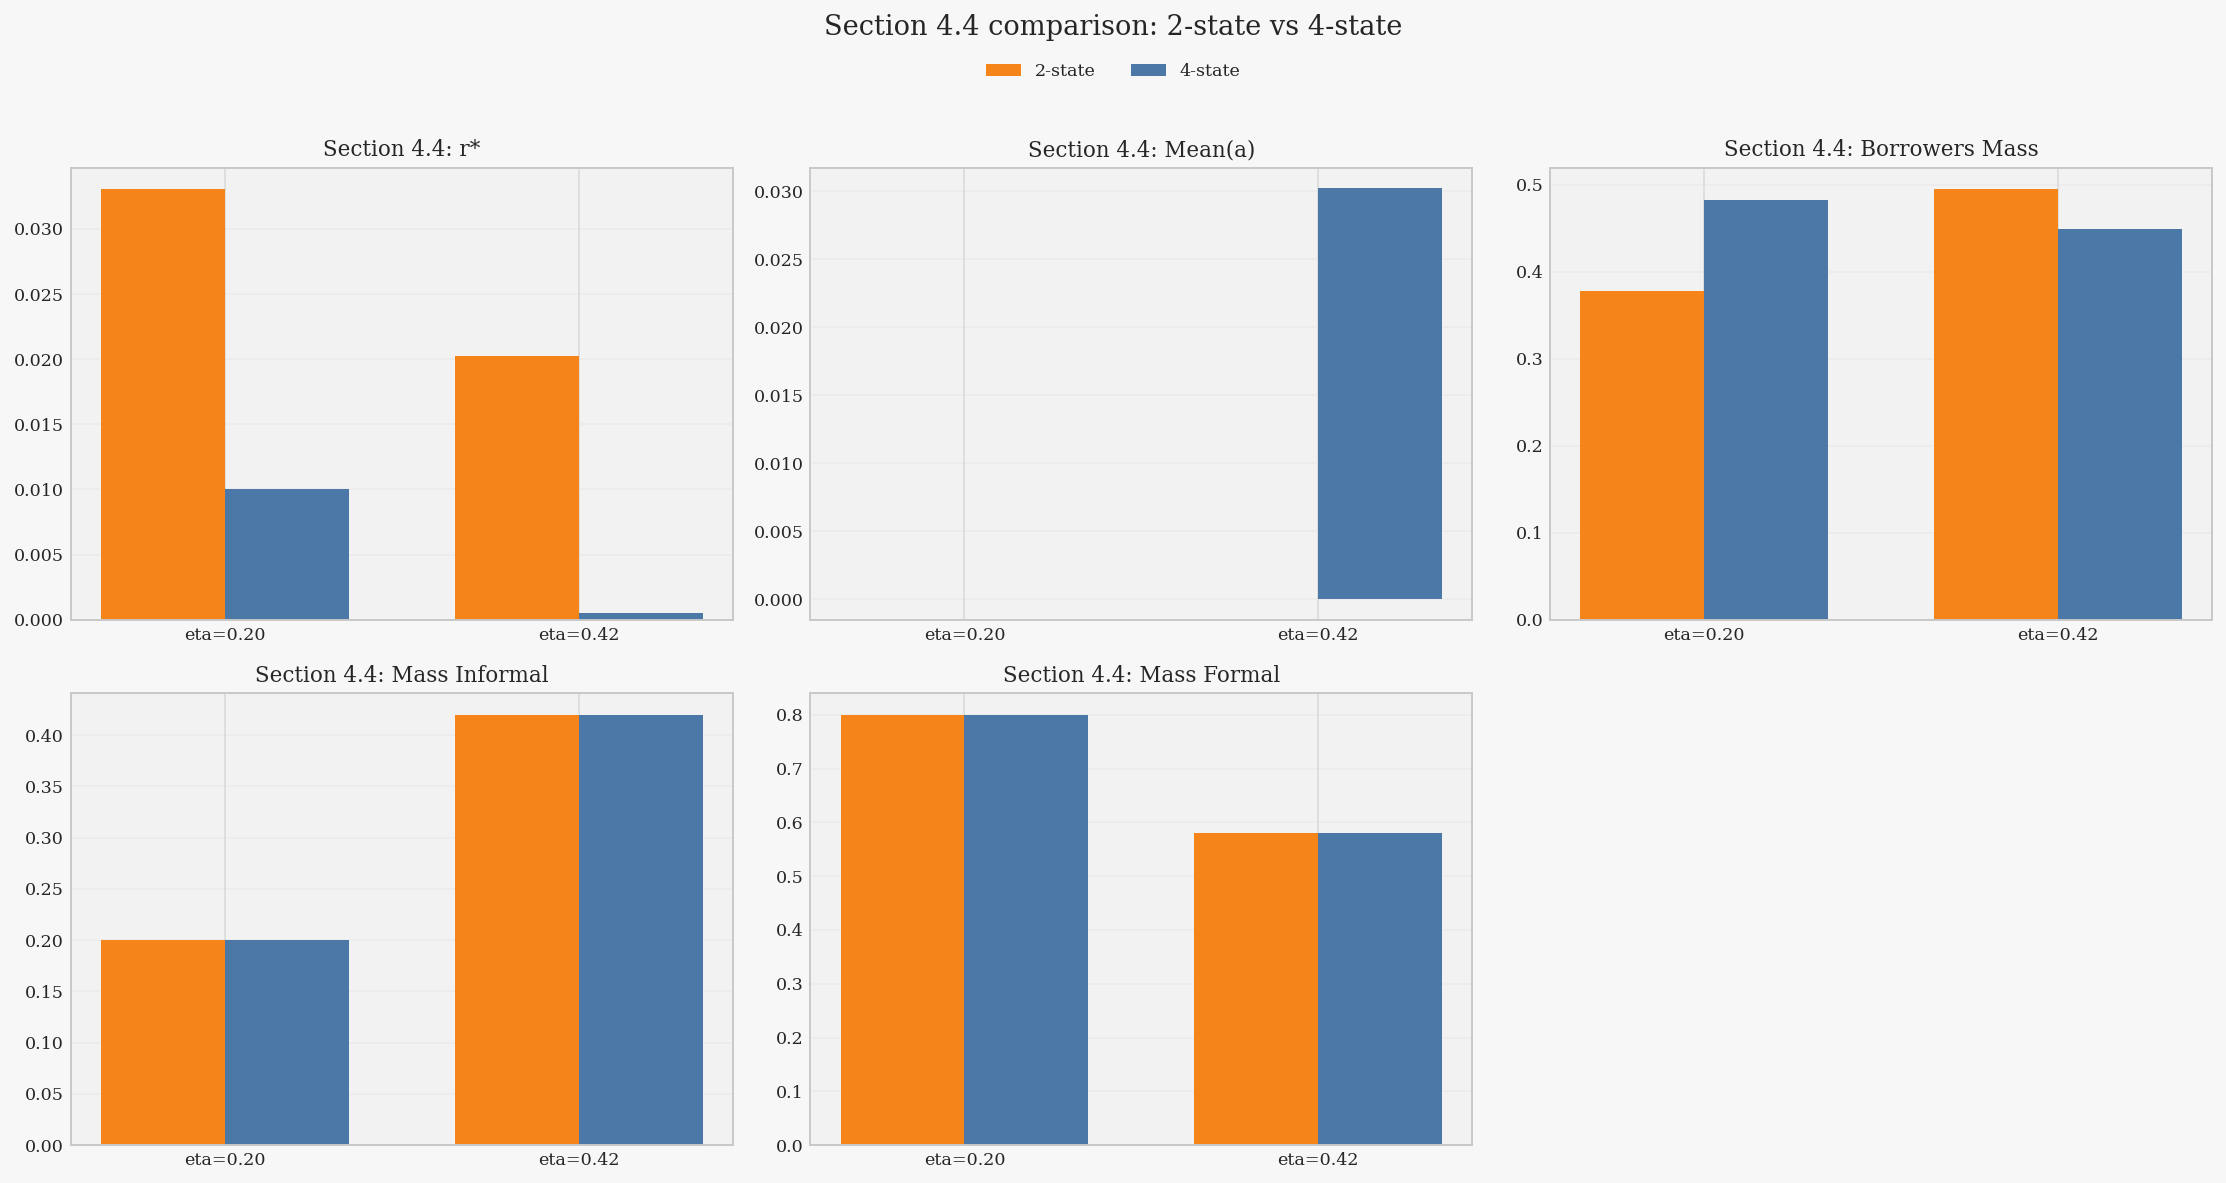

In [14]:
# Comparison 1: Section 4.4 (2-state vs 4-state)

sec44_2 = extract_section(long_2, "4.4", "2-state")
sec44_4 = extract_section(long_4, "4.4", "4-state")
sec44 = pd.concat([sec44_2, sec44_4], ignore_index=True)

if sec44.empty:
    raise RuntimeError("No 4.4 data found in one or both CSV files.")

eta_values_44 = sorted(sec44["eta"].dropna().unique())
print("Section 4.4 comparison table (sample):")
print(sec44.sort_values(["metric", "eta", "model"]).head(12).to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()
colors = {"2-state": "#f58518", "4-state": "#4c78a8"}

for i, metric in enumerate(metrics_keep):
    ax = axes[i]
    sub = sec44[sec44["metric"] == metric].copy()
    if sub.empty:
        ax.set_title(f"No data: {metric}")
        continue

    x = np.arange(len(eta_values_44))
    width = 0.35

    vals2 = [sub[(sub["model"] == "2-state") & (np.isclose(sub["eta"], e))]["value"].iloc[0] if len(sub[(sub["model"] == "2-state") & (np.isclose(sub["eta"], e))]) else np.nan for e in eta_values_44]
    vals4 = [sub[(sub["model"] == "4-state") & (np.isclose(sub["eta"], e))]["value"].iloc[0] if len(sub[(sub["model"] == "4-state") & (np.isclose(sub["eta"], e))]) else np.nan for e in eta_values_44]

    ax.bar(x - width / 2, vals2, width=width, color=colors["2-state"], label="2-state")
    ax.bar(x + width / 2, vals4, width=width, color=colors["4-state"], label="4-state")
    ax.set_xticks(x)
    ax.set_xticklabels([f"eta={e:.2f}" for e in eta_values_44])
    ax.set_title(f"Section 4.4: {metric}")
    ax.grid(axis="y", alpha=0.3)

# Hide unused subplot slot
for j in range(len(metrics_keep), len(axes)):
    axes[j].axis("off")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("Section 4.4 comparison: 2-state vs 4-state", y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

Section 4.1 macro comparison (2-state vs 4-state):
  model section  eta         metric     value
2-state     4.1  0.2 Borrowers Mass  0.415968
4-state     4.1  0.2 Borrowers Mass  0.509942
2-state     4.1 0.42 Borrowers Mass  0.523715
4-state     4.1 0.42 Borrowers Mass  0.556186
2-state     4.1  0.2             r* 0.0406342
4-state     4.1  0.2             r* 0.0229923
2-state     4.1 0.42             r* 0.0339072
4-state     4.1 0.42             r* 0.0189771


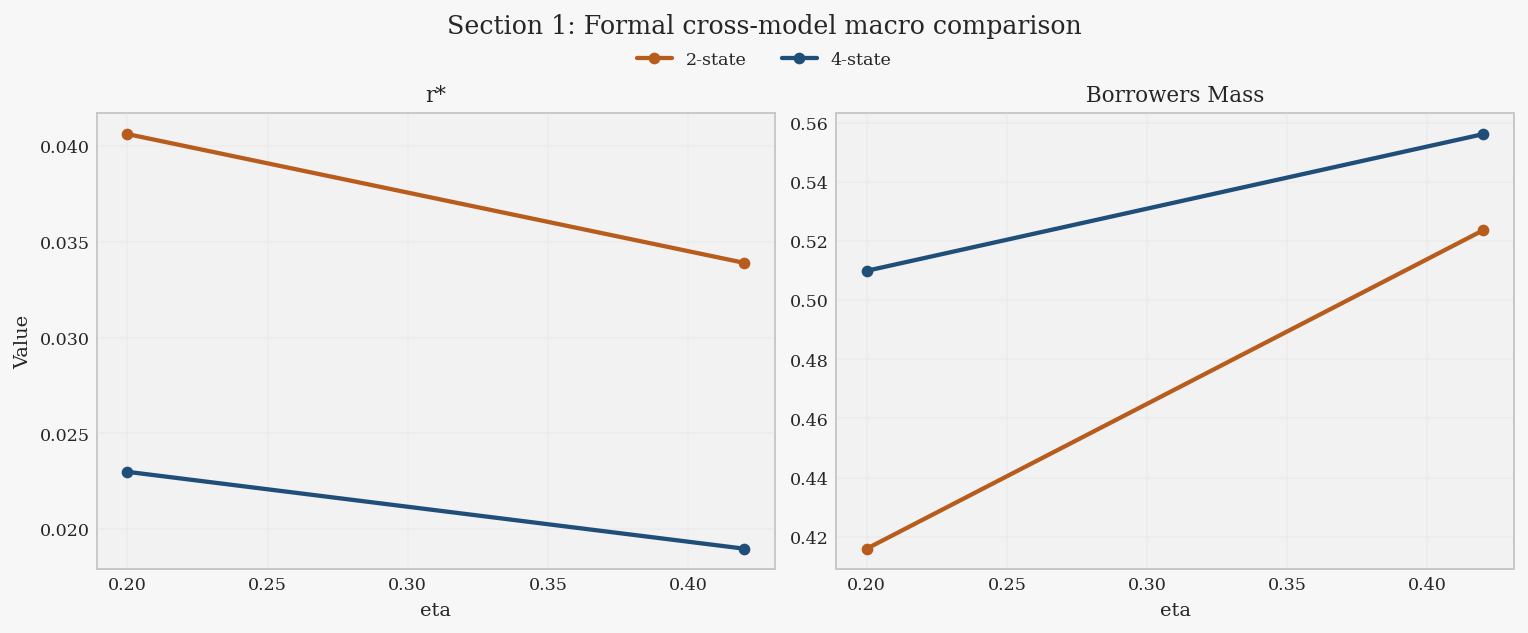

In [15]:
# Comparison 2 (refined): Section 4.1 macro moments (2-state vs 4-state)

sec41_2 = extract_section(long_2, "4.1", "2-state")
sec41_4 = extract_section(long_4, "4.1", "4-state")
sec41 = pd.concat([sec41_2, sec41_4], ignore_index=True)

if sec41.empty:
    raise RuntimeError("No 4.1 data found in one or both CSV files.")

eta_values_41 = sorted(sec41["eta"].dropna().unique())
macro_metrics = ["r*", "Borrowers Mass"]
palette = {"2-state": "#b85c1e", "4-state": "#1f4e79"}

print("Section 4.1 macro comparison (2-state vs 4-state):")
print(
    sec41[sec41["metric"].isin(macro_metrics)]
    .sort_values(["metric", "eta", "model"])
    .to_string(index=False, float_format=lambda x: f"{x:.6g}")
)

fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.9), constrained_layout=True)

for ax, metric in zip(axes, macro_metrics):
    sub = sec41[sec41["metric"] == metric].copy()

    for model in ["2-state", "4-state"]:
        m = sub[sub["model"] == model].sort_values("eta")
        ax.plot(
            m["eta"],
            m["value"],
            marker="o",
            markersize=5,
            linewidth=2.2,
            color=palette[model],
            label=model,
        )

    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Value")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.suptitle("Section 1: Formal cross-model macro comparison", y=1.12, fontsize=13)
plt.show()

3x3 reform-effect comparison: (C-A)4-state minus (C-A)2-state
model_4   eta        metric  effect_C_minus_A_4 model_2  effect_C_minus_A_2  diff_effect
4-state   0.2   Mass Formal           0.0914868 2-state                0.02    0.0714868
4-state  0.42   Mass Formal            0.158973 2-state               0.042     0.116973
4-state   0.2 Mass Informal          -0.0914868 2-state               -0.02   -0.0714868
4-state  0.42 Mass Informal           -0.158973 2-state              -0.042    -0.116973
4-state   0.2            r*         -0.00376672 2-state         -0.00126358  -0.00250314
4-state  0.42            r*         -0.00447974 2-state         -0.00257843  -0.00190131


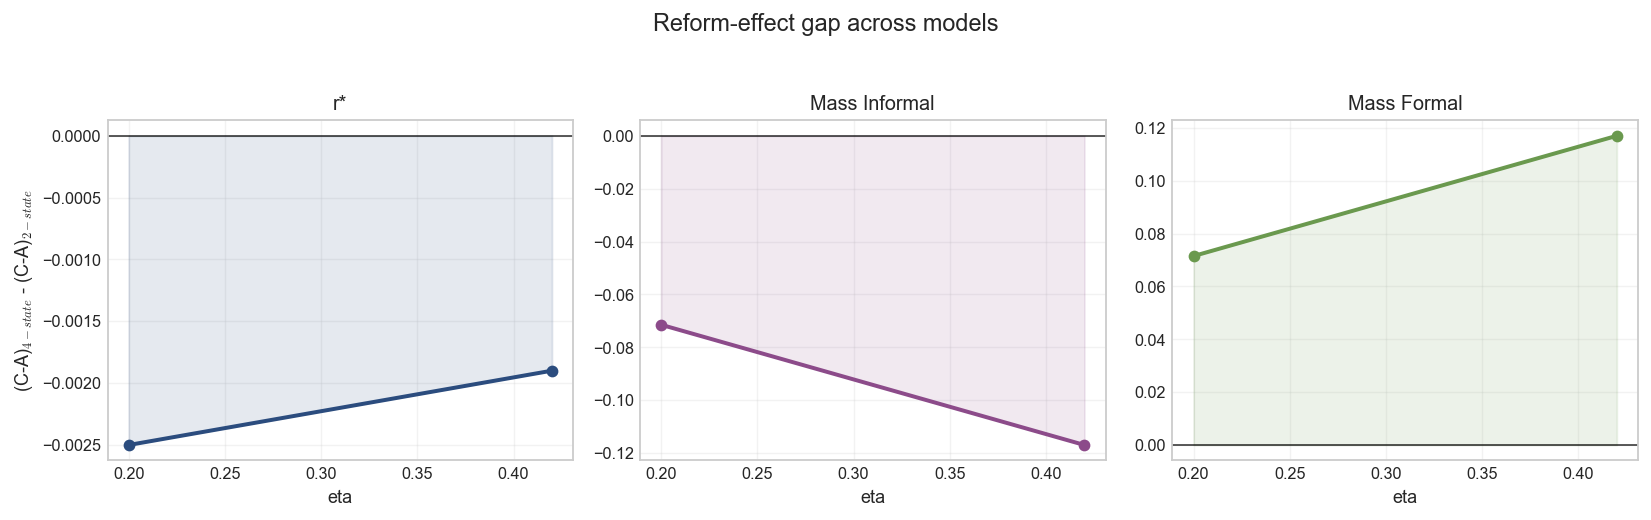

In [16]:
# 3x3 policy comparison: (C - A) in 4-state minus (C - A) in 2-state
# This focuses on the shared reform metrics and keeps the design compact for thesis use.

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

# Reuse loaded data if available; otherwise load from disk.
if "long_2" not in globals() or "long_4" not in globals():
    def find_project_root(start: Path) -> Path:
        for p in [start, *start.parents]:
            if (p / "1. data").exists() and (p / "2. code").exists():
                return p
        return start

    project_root = find_project_root(Path.cwd())
    output_dir = project_root / "1. data" / "output_data"
    long_2 = pd.read_csv(output_dir / "equilibrium_2state_arg_all_results_long.csv", low_memory=False)
    long_4 = pd.read_csv(output_dir / "equilibrium_4state_arg_all_results_long.csv", low_memory=False)

for df in (long_2, long_4):
    df["eta"] = pd.to_numeric(df["eta"], errors="coerce")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")

# Common metric labels across both exports.
metric_map_4 = {"r*": "r*", "mass_informal": "Mass Informal", "mass_formal": "Mass Formal"}
metric_map_2 = {"r*": "r*", "Mass Informal": "Mass Informal", "Mass Formal": "Mass Formal"}
metric_order = ["r*", "Mass Informal", "Mass Formal"]

# 4-state: C-A = lambda_change - baseline_2024, evaluated under the find_equilibrium option.
df4 = long_4[
    (long_4["data_kind"] == "table")
    & (long_4["source"] == "df_3x3")
    & (long_4["option"] == "find_equilibrium")
    & (long_4["model"].isin(["baseline_2024", "lambda_change"]))
    & (long_4["scenario"].isin(metric_map_4.keys()))
].copy()
df4["metric"] = df4["scenario"].map(metric_map_4)

# 2-state: C-A = C_simplified_plus_lambda - A_baseline_2024.
df2 = long_2[
    (long_2["data_kind"] == "table")
    & (long_2["source"] == "reform2_df_main")
    & (long_2["model"].isin(["A_baseline_2024", "C_simplified_plus_lambda"]))
    & (long_2["scenario"].isin(metric_map_2.keys()))
].copy()
df2["metric"] = df2["scenario"].map(metric_map_2)

if df4.empty or df2.empty:
    raise RuntimeError("Could not find the required 3x3 comparison rows in one or both exports.")

# Build reform-effect tables.
def make_effect_table(df: pd.DataFrame, model_label: str, model_a: str, model_c: str) -> pd.DataFrame:
    rows = []
    for eta in sorted(df["eta"].dropna().unique()):
        sub = df[np.isclose(df["eta"], eta)]
        for metric in metric_order:
            a_val = sub[(sub["model"] == model_a) & (sub["metric"] == metric)]["value"]
            c_val = sub[(sub["model"] == model_c) & (sub["metric"] == metric)]["value"]
            if len(a_val) == 0 or len(c_val) == 0:
                continue
            rows.append({
                "model": model_label,
                "eta": float(eta),
                "metric": metric,
                "effect_C_minus_A": float(c_val.iloc[0] - a_val.iloc[0]),
            })
    return pd.DataFrame(rows)

fx4 = make_effect_table(df4, "4-state", "baseline_2024", "lambda_change")
fx2 = make_effect_table(df2, "2-state", "A_baseline_2024", "C_simplified_plus_lambda")

comparison = fx4.merge(fx2, on=["eta", "metric"], suffixes=("_4", "_2"))
comparison["diff_effect"] = comparison["effect_C_minus_A_4"] - comparison["effect_C_minus_A_2"]

print("3x3 reform-effect comparison: (C-A)4-state minus (C-A)2-state")
print(comparison.sort_values(["metric", "eta"]).to_string(index=False, float_format=lambda x: f"{x: .6g}"))

# Elegant thesis-style visualization: one compact figure with 3 small panels.
fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.8), sharey=False)
palette = {"r*": "#2b4c7e", "Mass Informal": "#8c4b8a", "Mass Formal": "#6a994e"}

for ax, metric in zip(axes, metric_order):
    sub = comparison[comparison["metric"] == metric].sort_values("eta")
    if sub.empty:
        ax.set_title(f"{metric}: no data")
        continue

    ax.axhline(0, color="black", linewidth=1, alpha=0.7)
    ax.plot(
        sub["eta"],
        sub["diff_effect"],
        color=palette[metric],
        marker="o",
        linewidth=2.2,
        markersize=5.5,
    )
    ax.fill_between(sub["eta"], 0, sub["diff_effect"], color=palette[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("(C-A)$_{4-state}$ - (C-A)$_{2-state}$")
fig.suptitle("Reform-effect gap across models", y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

Consumption and savings reform-effect gap: (C-A)4-state - (C-A)2-state
  eta      metric  effect_4state  effect_2state  gap_4minus2
 0.42 consumption        0.10035      0.0600038    0.0403466
 0.42     savings   -4.01302e-15    1.13362e-17 -4.02436e-15


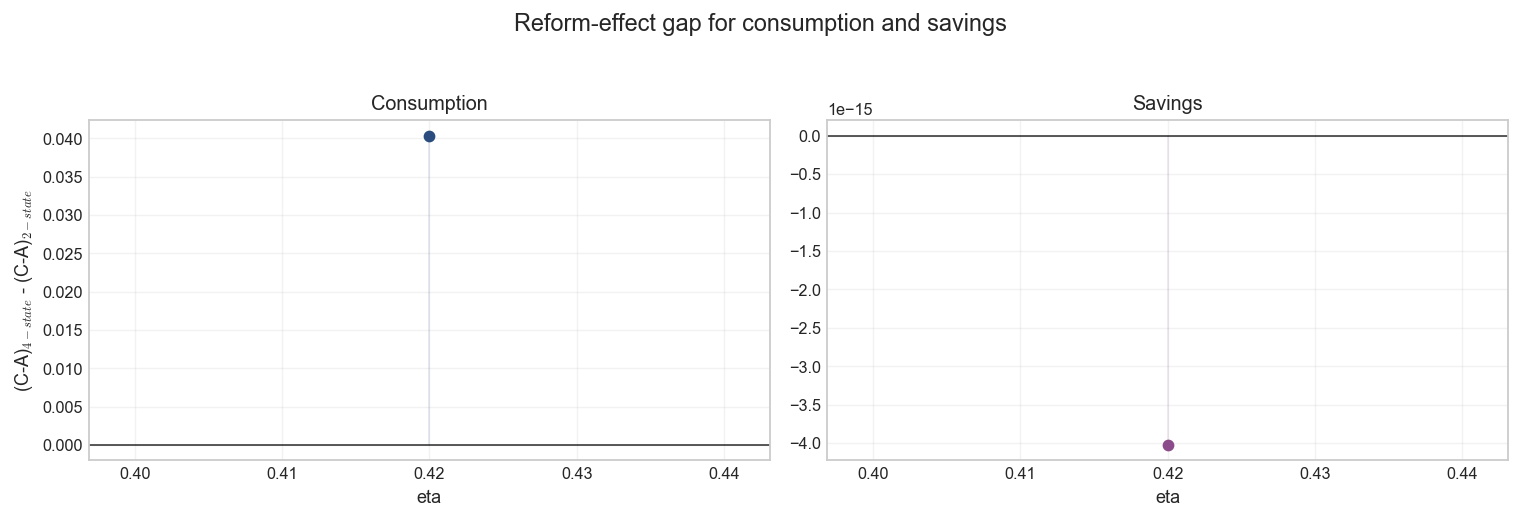

In [17]:
# Consumption and savings: (C - A) reform-effect gap across models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 130,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

metric_list = ["consumption", "savings"]
model_pairs = {
    "4-state": {"A": "baseline_2024", "C": "lambda_change", "source": "final_3x3_series", "option": "find_equilibrium"},
    "2-state": {"A": "A_baseline_2024", "C": "C_simplified_plus_lambda", "source": "final_2state_reform_series", "option": None},
}


def _weighted_mean_policy(df_series: pd.DataFrame, metric_name: str, model_name: str, eta_value: float, source_name: str, option_name: str | None):
    policy = df_series[
        (df_series["source"] == source_name)
        & (df_series["data_kind"] == "series")
        & (df_series["metric"] == metric_name)
        & (df_series["model"] == model_name)
        & (np.isclose(df_series["eta"], eta_value))
    ].copy()

    density = df_series[
        (df_series["source"] == source_name)
        & (df_series["data_kind"] == "series")
        & (df_series["metric"] == "density")
        & (df_series["model"] == model_name)
        & (np.isclose(df_series["eta"], eta_value))
    ].copy()

    if option_name is not None:
        policy = policy[policy["option"] == option_name]
        density = density[density["option"] == option_name]

    if policy.empty or density.empty:
        return np.nan

    merged = policy.merge(
        density[["model", "eta", "state", "grid_index", "value"]].rename(columns={"value": "density"}),
        on=["model", "eta", "state", "grid_index"],
        how="inner",
    )

    if merged.empty:
        return np.nan

    grid_vals = np.sort(merged["grid_value"].dropna().unique())
    da = float(np.median(np.diff(grid_vals))) if len(grid_vals) > 1 else 1.0

    weighted_num = float((merged["value"] * merged["density"]).sum() * da)
    weighted_den = float(merged["density"].sum() * da)
    if abs(weighted_den) < 1e-14:
        return np.nan
    return weighted_num / weighted_den


comparison_rows = []
eta_4 = sorted(
    long_4[
        (long_4["source"] == "final_3x3_series")
        & (long_4["data_kind"] == "series")
        & (long_4["model"].isin(["baseline_2024", "lambda_change"]))
        & (long_4["option"] == "find_equilibrium")
    ]["eta"].dropna().unique()
)
eta_2 = sorted(
    long_2[
        (long_2["source"] == "final_2state_reform_series")
        & (long_2["data_kind"] == "series")
        & (long_2["model"].isin(["A_baseline_2024", "C_simplified_plus_lambda"]))
    ]["eta"].dropna().unique()
)
eta_grid = sorted(set(eta_4).intersection(set(eta_2)))

for eta_value in eta_grid:
    for metric_name in metric_list:
        effect_values = {}
        for model_label, spec in model_pairs.items():
            df_use = long_4 if model_label == "4-state" else long_2
            a_val = _weighted_mean_policy(
                df_use,
                metric_name=metric_name,
                model_name=spec["A"],
                eta_value=eta_value,
                source_name=spec["source"],
                option_name=spec["option"],
            )
            c_val = _weighted_mean_policy(
                df_use,
                metric_name=metric_name,
                model_name=spec["C"],
                eta_value=eta_value,
                source_name=spec["source"],
                option_name=spec["option"],
            )
            if np.isnan(a_val) or np.isnan(c_val):
                effect_values[model_label] = np.nan
            else:
                effect_values[model_label] = c_val - a_val

        if any(np.isnan(effect_values[m]) for m in ["4-state", "2-state"]):
            continue

        comparison_rows.append({
            "eta": float(eta_value),
            "metric": metric_name,
            "effect_4state": effect_values["4-state"],
            "effect_2state": effect_values["2-state"],
            "gap_4minus2": effect_values["4-state"] - effect_values["2-state"],
        })

cmp_cs = pd.DataFrame(comparison_rows)

if cmp_cs.empty:
    raise RuntimeError("No consumption/savings comparison rows could be constructed from the exported series.")

print("Consumption and savings reform-effect gap: (C-A)4-state - (C-A)2-state")
print(cmp_cs.sort_values(["metric", "eta"]).to_string(index=False, float_format=lambda x: f"{x: .6g}"))

fig, axes = plt.subplots(1, 2, figsize=(11.8, 3.8), sharey=False)
metric_titles = {"consumption": "Consumption", "savings": "Savings"}
metric_colors = {"consumption": "#2b4c7e", "savings": "#8c4b8a"}

for ax, metric_name in zip(axes, metric_list):
    sub = cmp_cs[cmp_cs["metric"] == metric_name].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1, alpha=0.7)
    ax.plot(
        sub["eta"],
        sub["gap_4minus2"],
        color=metric_colors[metric_name],
        marker="o",
        linewidth=2.2,
        markersize=5.5,
    )
    ax.fill_between(sub["eta"], 0, sub["gap_4minus2"], color=metric_colors[metric_name], alpha=0.12)
    ax.set_title(metric_titles[metric_name])
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("(C-A)$_{4-state}$ - (C-A)$_{2-state}$")
fig.suptitle("Reform-effect gap for consumption and savings", y=1.04, fontsize=13)
plt.tight_layout()
plt.show()

Section 4.1 policy comparison at eta=0.42


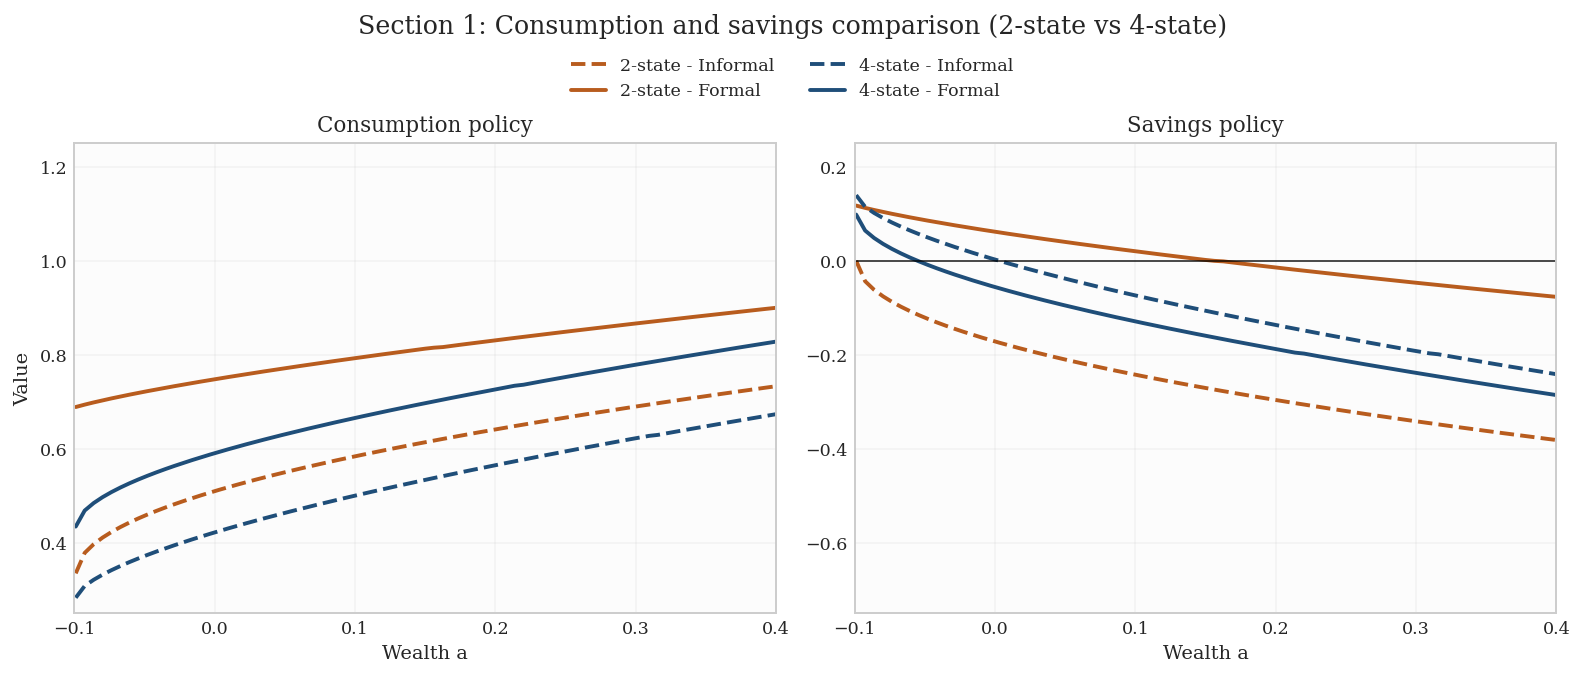

In [18]:
# Comparison 2b (new): Section 4.1 policy functions (consumption and savings)
# We use the section 4.1 side from comparison_4_1_vs_4_2 series (scenario='left').

metric_list = ["consumption", "savings"]
state_order = ["Informal", "Formal"]

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": 'serif',
    "figure.dpi": 140,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.facecolor": "#fcfcfc",
    "figure.facecolor": "white",
})

series_2 = long_2[
    (long_2["source"] == "comparison_4_1_vs_4_2")
    & (long_2["data_kind"] == "series")
    & (long_2["scenario"] == "left")
    & (long_2["metric"].isin(metric_list))
    & (long_2["state"].isin(state_order))
].copy()
series_2["model"] = "2-state"
series_2["state_group"] = series_2["state"]

series_4_raw = long_4[
    (long_4["source"] == "comparison_4_1_vs_4_2")
    & (long_4["data_kind"] == "series")
    & (long_4["scenario"] == "left")
    & (long_4["metric"].isin(metric_list))
].copy()

state_map_4 = {
    "HI Informal": "Informal",
    "LI Informal": "Informal",
    "HI Formal": "Formal",
    "LI Formal": "Formal",
}
series_4_raw["state_group"] = series_4_raw["state"].map(state_map_4)

# For 4-state, average policy functions within each sector (informal/formal).
series_4 = (
    series_4_raw.dropna(subset=["state_group"])
    .groupby(["eta", "metric", "grid_index", "grid_value", "state_group"], as_index=False)["value"]
    .mean()
)
series_4["model"] = "4-state"

series_all = pd.concat(
    [
        series_2[["eta", "metric", "grid_index", "grid_value", "state_group", "value", "model"]],
        series_4[["eta", "metric", "grid_index", "grid_value", "state_group", "value", "model"]],
    ],
    ignore_index=True,
)

if series_all.empty:
    raise RuntimeError("No section 4.1 consumption/savings series found for comparison.")

common_eta = sorted(set(series_2["eta"].dropna().unique()).intersection(set(series_4["eta"].dropna().unique())))
if len(common_eta) == 0:
    raise RuntimeError("No common eta values available for section 4.1 policy comparison.")

eta_focus = float(max(common_eta))
plot_df = series_all[np.isclose(series_all["eta"], eta_focus)].copy()

print(f"Section 4.1 policy comparison at eta={eta_focus:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.0), constrained_layout=True)
fig.patch.set_facecolor("white")
model_colors = {"2-state": "#b85c1e", "4-state": "#1f4e79"}
state_styles = {"Informal": "--", "Formal": "-"}
state_labels = {"Informal": "Informal", "Formal": "Formal"}
metric_titles = {"consumption": "Consumption policy", "savings": "Savings policy"}

for ax, metric in zip(axes, metric_list):
    sub_m = plot_df[plot_df["metric"] == metric]

    for model in ["2-state", "4-state"]:
        for state in state_order:
            s = sub_m[(sub_m["model"] == model) & (sub_m["state_group"] == state)].sort_values("grid_index")
            if s.empty:
                continue
            ax.plot(
                s["grid_value"],
                s["value"],
                color=model_colors[model],
                linestyle=state_styles[state],
                linewidth=2.0,
                label=f"{model} - {state_labels[state]}",
            )

    if metric == "savings":
        ax.axhline(0, color="black", linewidth=1, alpha=0.7)

    ax.set_title(metric_titles[metric])
    ax.set_xlabel("Wealth a")
    ax.set_xlim(-0.1, 0.4)
    if metric == "consumption":
        ax.set_ylim(0.25, 1.25)
    else:
        ax.set_ylim(-0.75, 0.25)
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

axes[0].set_ylabel("Value")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.12))
fig.suptitle("Section 1: Consumption and savings comparison (2-state vs 4-state)", y=1.17, fontsize=13)
plt.show()

In [19]:
series_4_raw

,source,data_kind,section,metric,state,eta,model,option,scenario,grid_var,grid_index,grid_value,value,state_group
760,comparison_4_1_vs_4_2,series,comparison_4_1_vs_4_2,consumption,HI Informal,0.42,NaN,NaN,left,a,0.0,-0.099000,0.390757,Informal
762,comparison_4_1_vs_4_2,series,comparison_4_1_vs_4_2,consumption,HI Informal,0.42,NaN,NaN,left,a,1.0,-0.092618,0.399856,Informal
764,comparison_4_1_vs_4_2,series,comparison_4_1_vs_4_2,consumption,HI Informal,0.42,NaN,NaN,left,a,2.0,-0.086237,0.408000,Informal
766,comparison_4_1_vs_4_2,series,comparison_4_1_vs_4_2,consumption,HI Informal,0.42,NaN,NaN,left,a,3.0,-0.079855,0.415540,Informal
768,comparison_4_1_vs_4_2,series,comparison_4_1_vs_4_2,consumption,HI Informal,0.42,NaN,NaN,left,a,4.0,-0.073473,0.422641,Informal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13550,comparison_4_1_vs_4_2,series,comparison_4_1_vs_4_2,savings,LI Formal,0.42,NaN,NaN,left,a,795.0,4.974473,-1.895639,Formal
13552,comparison_4_1_vs_4_2,series,comparison_4_1_vs_4_2,savings,LI Formal,0.42,NaN,NaN,left,a,796.0,4.980855,-1.897284,Formal
13554,comparison_4_1_vs_4_2,series,comparison_4_1_vs_4_2,savings,LI Formal,0.42,NaN,NaN,left,a,797.0,4.987237,-1.898929,Formal
13556,comparison_4_1_vs_4_2,series,comparison_4_1_vs_4_2,savings,LI Formal,0.42,NaN,NaN,left,a,798.0,4.993618,-1.900574,Formal


Section 4.4 macro comparison (2-state vs 4-state):
  model section  eta         metric     value
2-state     4.4  0.2 Borrowers Mass  0.377621
4-state     4.4  0.2 Borrowers Mass   0.48187
2-state     4.4 0.42 Borrowers Mass  0.494752
4-state     4.4 0.42 Borrowers Mass  0.449436
2-state     4.4  0.2             r* 0.0330463
4-state     4.4  0.2             r* 0.0100609
2-state     4.4 0.42             r* 0.0202295
4-state     4.4 0.42             r*    0.0005


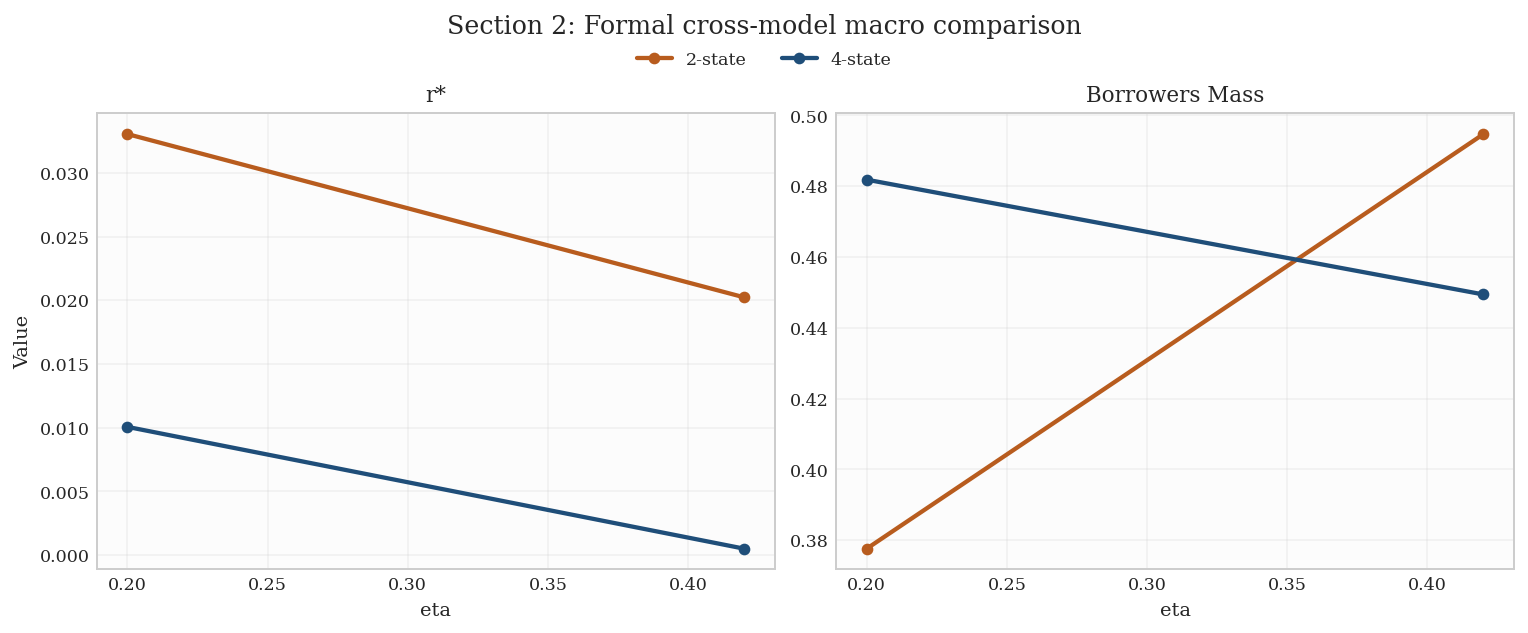

In [20]:
# Comparison 2 (refined): Section 4.4 macro moments (2-state vs 4-state)

sec44_2 = extract_section(long_2, "4.4", "2-state")
sec44_4 = extract_section(long_4, "4.4", "4-state")
sec44 = pd.concat([sec44_2, sec44_4], ignore_index=True)

if sec44.empty:
    raise RuntimeError("No 4.4 data found in one or both CSV files.")

eta_values_44 = sorted(sec44["eta"].dropna().unique())
macro_metrics = ["r*", "Borrowers Mass"]
palette = {"2-state": "#b85c1e", "4-state": "#1f4e79"}

print("Section 4.4 macro comparison (2-state vs 4-state):")
print(
    sec44[sec44["metric"].isin(macro_metrics)]
    .sort_values(["metric", "eta", "model"])
    .to_string(index=False, float_format=lambda x: f"{x:.6g}")
)

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": 'serif',
    "figure.dpi": 140,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.facecolor": "#fcfcfc",
    "figure.facecolor": "white",
})

fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.9), constrained_layout=True)

for ax, metric in zip(axes, macro_metrics):
    sub = sec44[sec44["metric"] == metric].copy()

    for model in ["2-state", "4-state"]:
        m = sub[sub["model"] == model].sort_values("eta")
        ax.plot(
            m["eta"],
            m["value"],
            marker="o",
            markersize=5,
            linewidth=2.2,
            color=palette[model],
            label=model,
        )

    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Value")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.suptitle("Section 2: Formal cross-model macro comparison", y=1.12, fontsize=13)
plt.show()

Section 4.4 policy comparison at eta=0.42


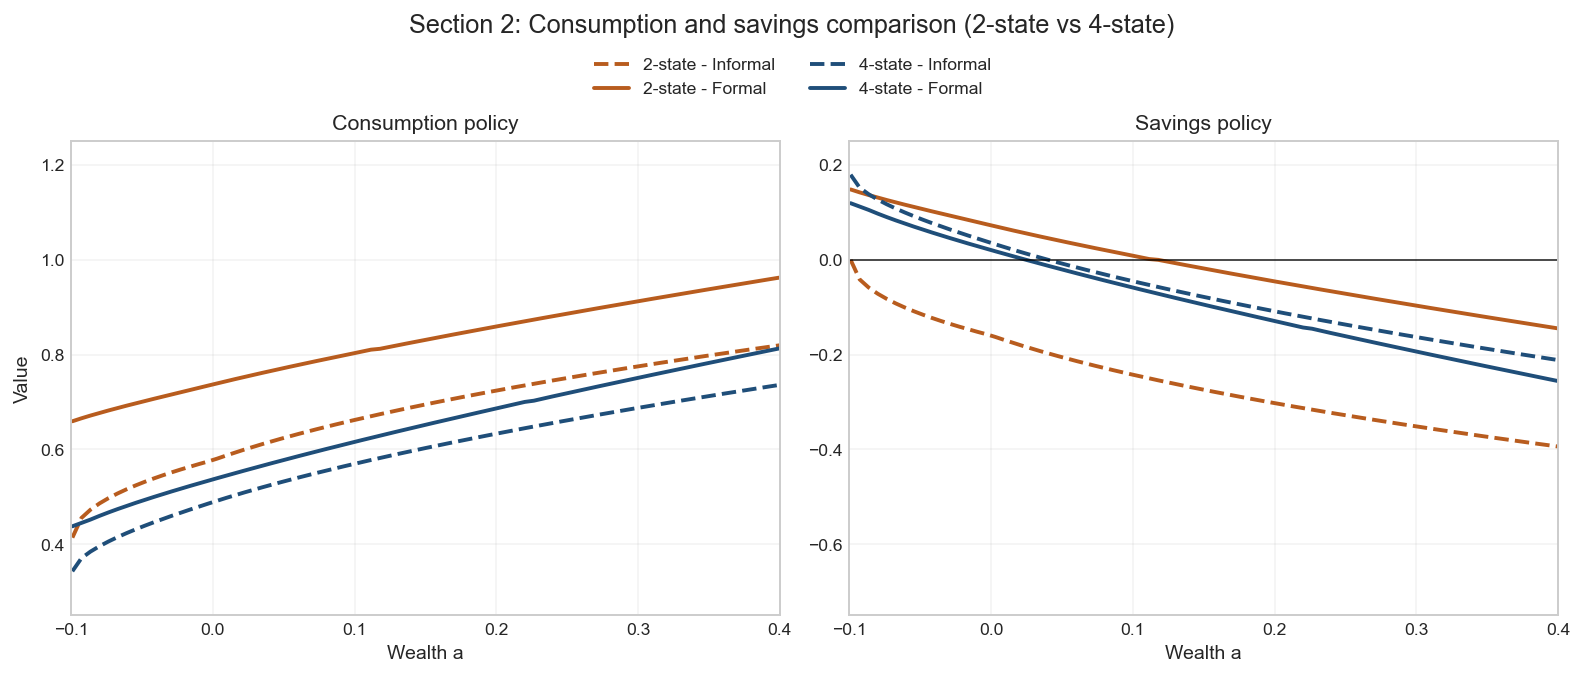

In [28]:
# Comparison 2b (new): Section 4.1 policy functions (consumption and savings)
# We use the section 4.1 side from comparison_4_1_vs_4_2 series (scenario='left').

metric_list = ["consumption", "savings"]
state_order = ["Informal", "Formal"]

series_2 = long_2[
    (long_2["source"] == "comparison_4_1_vs_4_4")
    & (long_2["data_kind"] == "series")
    & (long_2["scenario"] == "right")
    & (long_2["metric"].isin(metric_list))
    & (long_2["state"].isin(state_order))
].copy()
series_2["model"] = "2-state"
series_2["state_group"] = series_2["state"]

series_4_raw = long_4[
    (long_4["source"] == "comparison_4_1_vs_4_4")
    & (long_4["data_kind"] == "series")
    & (long_4["scenario"] == "right")
    & (long_4["metric"].isin(metric_list))
].copy()

state_map_4 = {
    "HI Informal": "Informal",
    "LI Informal": "Informal",
    "HI Formal": "Formal",
    "LI Formal": "Formal",
}
series_4_raw["state_group"] = series_4_raw["state"].map(state_map_4)

# For 4-state, average policy functions within each sector (informal/formal).
series_4 = (
    series_4_raw.dropna(subset=["state_group"])
.groupby(["eta", "metric", "grid_index", "grid_value", "state_group"], as_index=False)["value"]
    .mean()
)
series_4["model"] = "4-state"

series_all = pd.concat(
    [
        series_2[["eta", "metric", "grid_index", "grid_value", "state_group", "value", "model"]],
        series_4[["eta", "metric", "grid_index", "grid_value", "state_group", "value", "model"]],
    ],
    ignore_index=True,
)

if series_all.empty:
    raise RuntimeError("No section 4.4 consumption/savings series found for comparison.")

common_eta = sorted(set(series_2["eta"].dropna().unique()).intersection(set(series_4["eta"].dropna().unique())))
if len(common_eta) == 0:
    raise RuntimeError("No common eta values available for section 4.4 policy comparison.")

eta_focus = float(max(common_eta))
plot_df = series_all[np.isclose(series_all["eta"], eta_focus)].copy()

print(f"Section 4.4 policy comparison at eta={eta_focus:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.0), constrained_layout=True)
model_colors = {"2-state": "#b85c1e", "4-state": "#1f4e79"}
state_styles = {"Informal": "--", "Formal": "-"}
state_labels = {"Informal": "Informal", "Formal": "Formal"}
metric_titles = {"consumption": "Consumption policy", "savings": "Savings policy"}

for ax, metric in zip(axes, metric_list):
    sub_m = plot_df[plot_df["metric"] == metric]

    for model in ["2-state", "4-state"]:
        for state in state_order:
            s = sub_m[(sub_m["model"] == model) & (sub_m["state_group"] == state)].sort_values("grid_index")
            if s.empty:
                continue
            ax.plot(
                s["grid_value"],
                s["value"],
                color=model_colors[model],
                linestyle=state_styles[state],
                linewidth=2.0,
                label=f"{model} - {state_labels[state]}",
            )

    if metric == "savings":
        ax.axhline(0, color="black", linewidth=1, alpha=0.7)

    ax.set_title(metric_titles[metric])
    ax.set_xlabel("Wealth a")
    ax.set_xlim(-0.1, 0.4)
    if metric == "consumption":
        ax.set_ylim(0.25, 1.25)
    else:
        ax.set_ylim(-0.75, 0.25)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Value")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.12))
fig.suptitle("Section 2: Consumption and savings comparison (2-state vs 4-state)", y=1.17, fontsize=13)
plt.show()

2-state B-A pure tax effect (sample):
  eta             metric  effect_B_minus_A
  0.2        Consumption         0.0559996
 0.42        Consumption         0.0405997
  0.2 Government revenue            -0.056
 0.42 Government revenue           -0.0406
  0.2            Savings       2.89074e-16
 0.42            Savings      -1.19314e-15
  0.2      Total welfare         0.0319103
 0.42      Total welfare         0.0272614
  0.2                 r*       -0.00146332
 0.42                 r*       -0.00268524


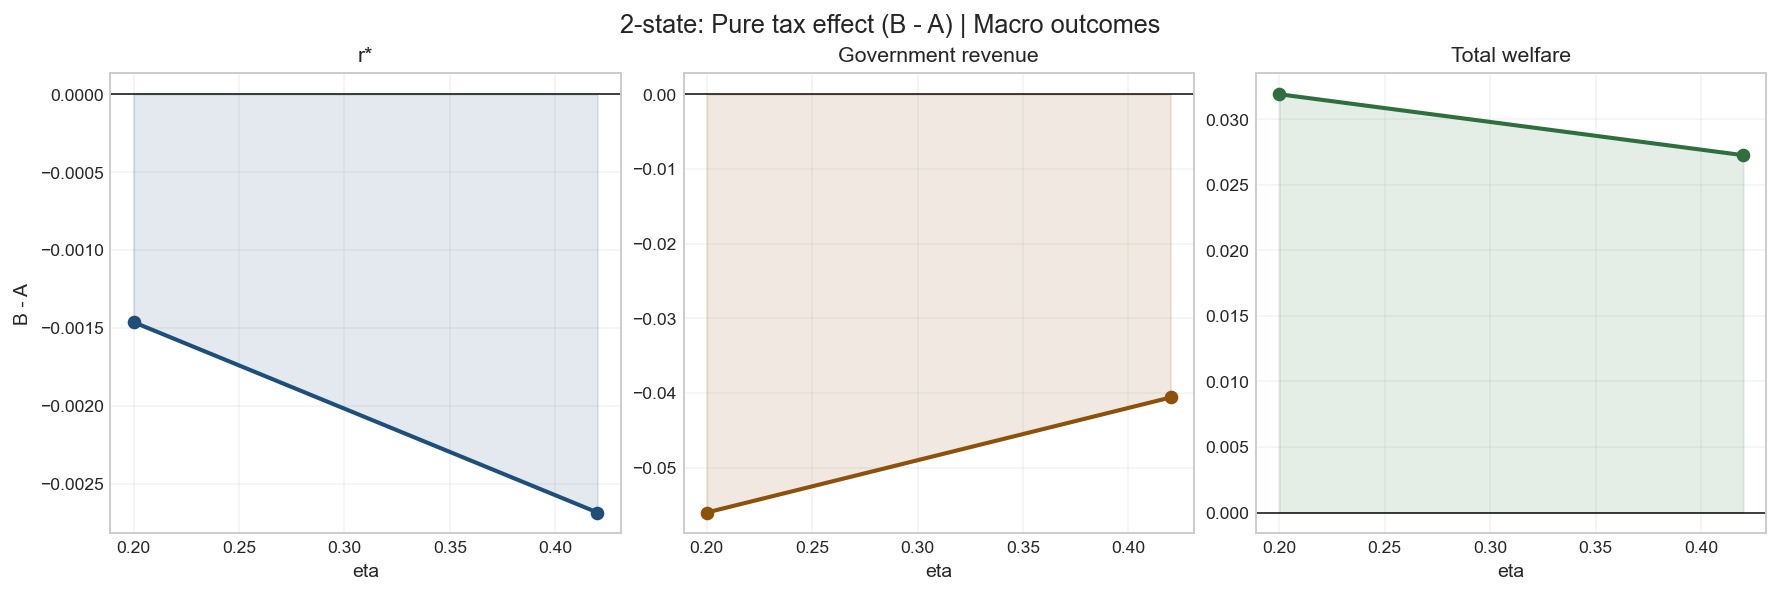

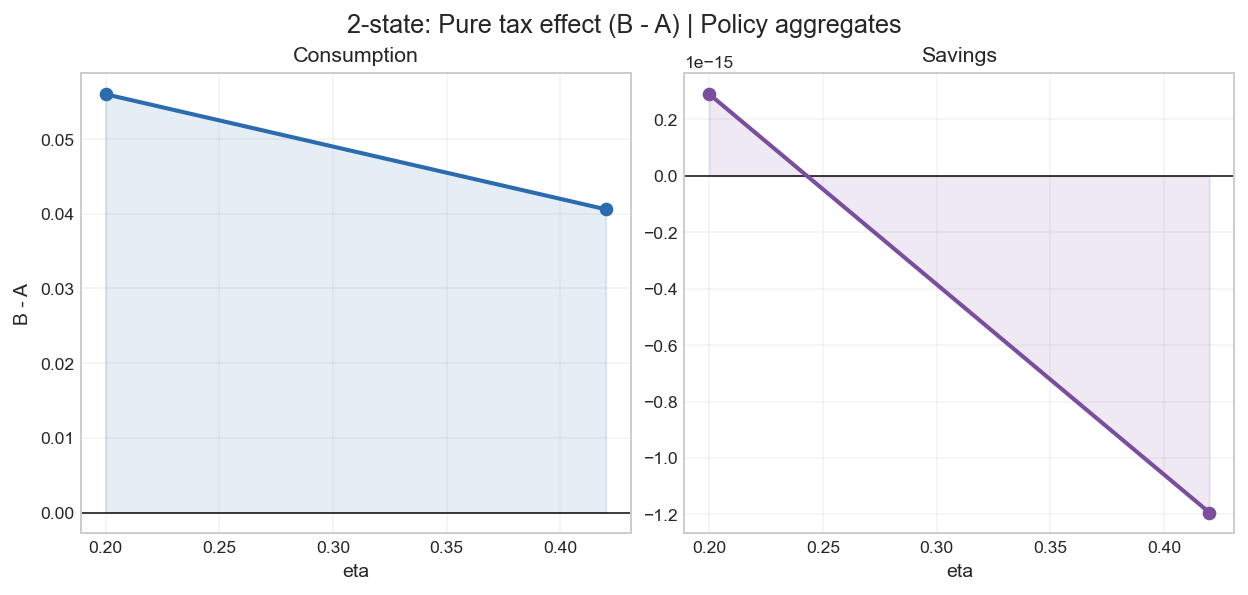

In [21]:
# B-A pure tax effect: 2-state (formal panel style)
# Metrics requested: consumption, savings, r*, welfare, government revenue.
# By design, figures are split so no panel has more than 3 charts.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 140,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

# ---------- 2-state macro B-A from reform tables ----------
# r* comes from reform2_df_main, while gov/welfare come from reform2_df_welfare_consumption.
rows_macro = []

# r*
tab2_r = long_2[
    (long_2["data_kind"] == "table")
    & (long_2["source"] == "reform2_df_main")
    & (long_2["model"].isin(["A_baseline_2024", "B_simplified_tax"]))
    & (long_2["scenario"] == "r*")
].copy()

for eta_val in sorted(tab2_r["eta"].dropna().unique()):
    sub = tab2_r[np.isclose(tab2_r["eta"], eta_val)]
    a = sub[sub["model"] == "A_baseline_2024"]["value"]
    b = sub[sub["model"] == "B_simplified_tax"]["value"]
    if len(a) and len(b):
        rows_macro.append({
            "eta": float(eta_val),
            "metric": "r*",
            "effect_B_minus_A": float(b.iloc[0] - a.iloc[0]),
        })

# Gov + welfare
tab2_w = long_2[
    (long_2["data_kind"] == "table")
    & (long_2["source"] == "reform2_df_welfare_consumption")
    & (long_2["model"].isin(["A_baseline_2024", "B_simplified_tax"]))
    & (long_2["scenario"].isin(["Gov (tax rev)", "Total welfare (lifetime)"]))
].copy()

metric_map_w = {
    "Gov (tax rev)": "Government revenue",
    "Total welfare (lifetime)": "Total welfare",
}

for eta_val in sorted(tab2_w["eta"].dropna().unique()):
    sub = tab2_w[np.isclose(tab2_w["eta"], eta_val)]
    for scen, metric_label in metric_map_w.items():
        a = sub[(sub["model"] == "A_baseline_2024") & (sub["scenario"] == scen)]["value"]
        b = sub[(sub["model"] == "B_simplified_tax") & (sub["scenario"] == scen)]["value"]
        if len(a) and len(b):
            rows_macro.append({
                "eta": float(eta_val),
                "metric": metric_label,
                "effect_B_minus_A": float(b.iloc[0] - a.iloc[0]),
            })

ba_macro_2 = pd.DataFrame(rows_macro)

# ---------- 2-state policy B-A from exported series ----------
def weighted_policy_mean_2(df_series: pd.DataFrame, metric_name: str, model_name: str, eta_val: float):
    policy = df_series[
        (df_series["source"] == "final_2state_reform_series")
        & (df_series["data_kind"] == "series")
        & (df_series["metric"] == metric_name)
        & (df_series["model"] == model_name)
        & (np.isclose(df_series["eta"], eta_val))
    ].copy()

    density = df_series[
        (df_series["source"] == "final_2state_reform_series")
        & (df_series["data_kind"] == "series")
        & (df_series["metric"] == "density")
        & (df_series["model"] == model_name)
        & (np.isclose(df_series["eta"], eta_val))
    ].copy()

    if policy.empty or density.empty:
        return np.nan

    merged = policy.merge(
        density[["model", "eta", "state", "grid_index", "value"]].rename(columns={"value": "density"}),
        on=["model", "eta", "state", "grid_index"],
        how="inner",
    )
    if merged.empty:
        return np.nan

    grid_vals = np.sort(merged["grid_value"].dropna().unique())
    da = float(np.median(np.diff(grid_vals))) if len(grid_vals) > 1 else 1.0

    num = float((merged["value"] * merged["density"]).sum() * da)
    den = float(merged["density"].sum() * da)
    return np.nan if abs(den) < 1e-14 else num / den

policy_rows = []
metric_titles = {"consumption": "Consumption", "savings": "Savings"}
eta_grid_2 = sorted(
    long_2[
        (long_2["source"] == "final_2state_reform_series")
        & (long_2["data_kind"] == "series")
        & (long_2["model"].isin(["A_baseline_2024", "B_simplified_tax"]))
    ]["eta"].dropna().unique()
)

for eta_val in eta_grid_2:
    for metric in ["consumption", "savings"]:
        a_val = weighted_policy_mean_2(long_2, metric, "A_baseline_2024", eta_val)
        b_val = weighted_policy_mean_2(long_2, metric, "B_simplified_tax", eta_val)
        if np.isnan(a_val) or np.isnan(b_val):
            continue
        policy_rows.append({
            "eta": float(eta_val),
            "metric": metric_titles[metric],
            "effect_B_minus_A": float(b_val - a_val),
        })

ba_policy_2 = pd.DataFrame(policy_rows)

if ba_macro_2.empty or ba_policy_2.empty:
    raise RuntimeError("Could not build complete B-A effects for 2-state from exported data.")

print("2-state B-A pure tax effect (sample):")
print(
    pd.concat([ba_macro_2, ba_policy_2], ignore_index=True)
    .sort_values(["metric", "eta"])
    .head(15)
    .to_string(index=False, float_format=lambda x: f"{x: .6g}")
)

# Figure A (max 3 charts): r*, gov, welfare
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.9), constrained_layout=True)
macro_order = ["r*", "Government revenue", "Total welfare"]
macro_colors = {
    "r*": "#1f4e79",
    "Government revenue": "#8c510a",
    "Total welfare": "#2f6f3e",
}

for ax, metric in zip(axes, macro_order):
    sub = ba_macro_2[ba_macro_2["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["effect_B_minus_A"], marker="o", linewidth=2.1, color=macro_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["effect_B_minus_A"], color=macro_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("B - A")
fig.suptitle("2-state: Pure tax effect (B - A) | Macro outcomes", y=1.05, fontsize=13)
plt.show()

# Figure B (max 3 charts): consumption, savings
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.9), constrained_layout=True)
policy_order = ["Consumption", "Savings"]
policy_colors = {"Consumption": "#2b6cb0", "Savings": "#7a4e9f"}

for ax, metric in zip(axes, policy_order):
    sub = ba_policy_2[ba_policy_2["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["effect_B_minus_A"], marker="o", linewidth=2.1, color=policy_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["effect_B_minus_A"], color=policy_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("B - A")
fig.suptitle("2-state: Pure tax effect (B - A) | Policy aggregates", y=1.05, fontsize=13)
plt.show()

4-state B-A pure tax effect (sample):
  eta             metric  effect_B_minus_A
  0.2        Consumption         0.0461272
 0.42        Consumption         0.0334424
  0.2 Government revenue         -0.010569
 0.42 Government revenue       -0.00766249
  0.2            Savings      -2.55305e-15
 0.42            Savings       9.97665e-17
  0.2      Total welfare          0.732184
 0.42      Total welfare          0.535747
  0.2                 r*        -0.0053584
 0.42                 r*       -0.00555646


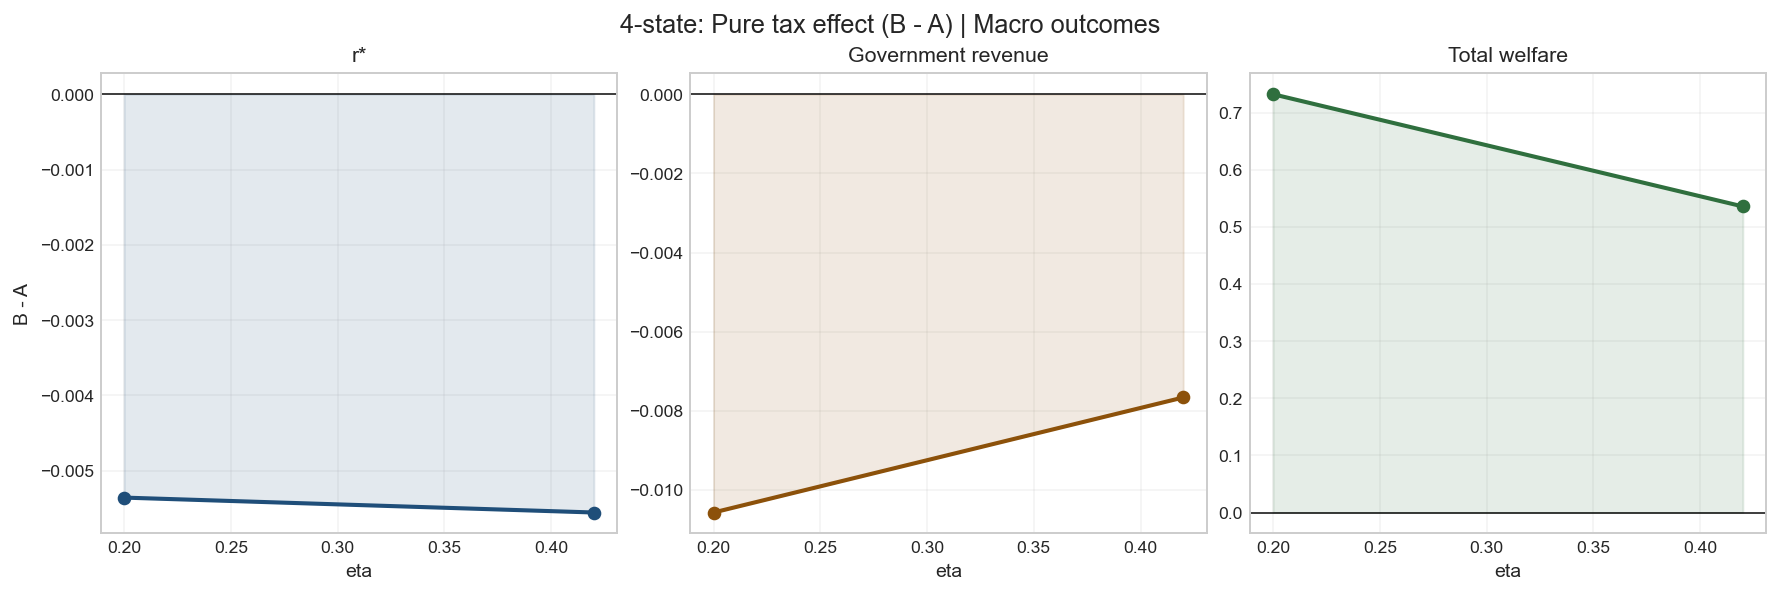

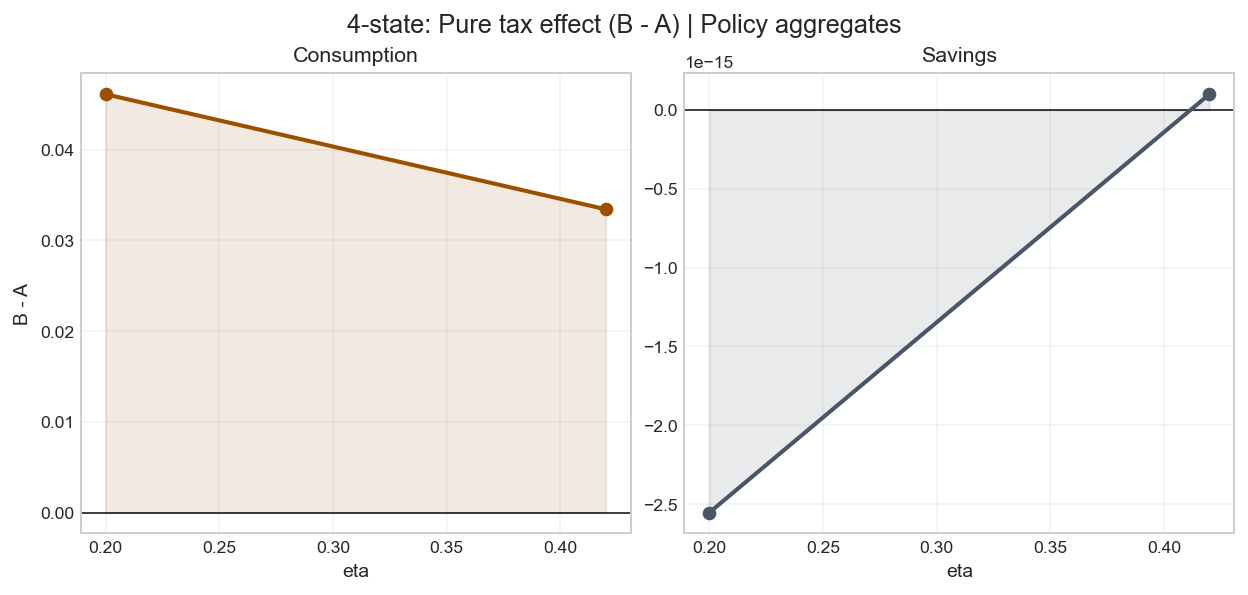

In [22]:
# B-A pure tax effect: 4-state (formal panel style)
# Metrics requested: consumption, savings, r*, welfare, government revenue.
# By design, figures are split so no panel has more than 3 charts.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 140,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

# ---------- 4-state macro + policy B-A from df_3x3 table ----------
# Now that avg_consumption and avg_savings are exported in df_3x3,
# we use one consistent source for all requested metrics.
metric_map_4 = {
    "r*": "r*",
    "gov": "Government revenue",
    "total_welfare": "Total welfare",
    "avg_consumption": "Consumption",
    "avg_savings": "Savings",
}

tab4 = long_4[
    (long_4["data_kind"] == "table")
    & (long_4["source"] == "df_3x3")
    & (long_4["option"] == "find_equilibrium")
    & (long_4["model"].isin(["baseline_2024", "tax_reform"]))
    & (long_4["scenario"].isin(metric_map_4.keys()))
].copy()

rows = []
for eta_val in sorted(tab4["eta"].dropna().unique()):
    sub = tab4[np.isclose(tab4["eta"], eta_val)]
    for src_metric, metric_label in metric_map_4.items():
        a = sub[(sub["model"] == "baseline_2024") & (sub["scenario"] == src_metric)]["value"]
        b = sub[(sub["model"] == "tax_reform") & (sub["scenario"] == src_metric)]["value"]
        if len(a) and len(b):
            rows.append({
                "eta": float(eta_val),
                "metric": metric_label,
                "effect_B_minus_A": float(b.iloc[0] - a.iloc[0]),
            })

effects_4 = pd.DataFrame(rows)

if effects_4.empty:
    raise RuntimeError("Could not build B-A effects for 4-state from df_3x3 export rows.")

print("4-state B-A pure tax effect (sample):")
print(
    effects_4.sort_values(["metric", "eta"]).to_string(index=False, float_format=lambda x: f"{x: .6g}")
)

# Figure A (max 3 charts): r*, gov, welfare
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.9), constrained_layout=True)
macro_order = ["r*", "Government revenue", "Total welfare"]
macro_colors = {
    "r*": "#1f4e79",
    "Government revenue": "#8c510a",
    "Total welfare": "#2f6f3e",
}

for ax, metric in zip(axes, macro_order):
    sub = effects_4[effects_4["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["effect_B_minus_A"], marker="o", linewidth=2.1, color=macro_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["effect_B_minus_A"], color=macro_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("B - A")
fig.suptitle("4-state: Pure tax effect (B - A) | Macro outcomes", y=1.05, fontsize=13)
plt.show()

# Figure B (max 3 charts): consumption, savings
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.9), constrained_layout=True)
policy_order = ["Consumption", "Savings"]
policy_colors = {"Consumption": "#9c4f00", "Savings": "#4a5568"}

for ax, metric in zip(axes, policy_order):
    sub = effects_4[effects_4["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["effect_B_minus_A"], marker="o", linewidth=2.1, color=policy_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["effect_B_minus_A"], color=policy_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("B - A")
fig.suptitle("4-state: Pure tax effect (B - A) | Policy aggregates", y=1.05, fontsize=13)
plt.show()

2-state C-A pure reform effect (sample):
  eta             metric  effect_C_minus_A
  0.2        Consumption         0.0652402
 0.42        Consumption         0.0600038
  0.2 Government revenue           -0.0536
 0.42 Government revenue          -0.03556
  0.2            Savings      -1.47371e-15
 0.42            Savings       1.13362e-17
  0.2      Total welfare          0.277976
 0.42      Total welfare          0.544365
  0.2                 r*       -0.00126358
 0.42                 r*       -0.00257843


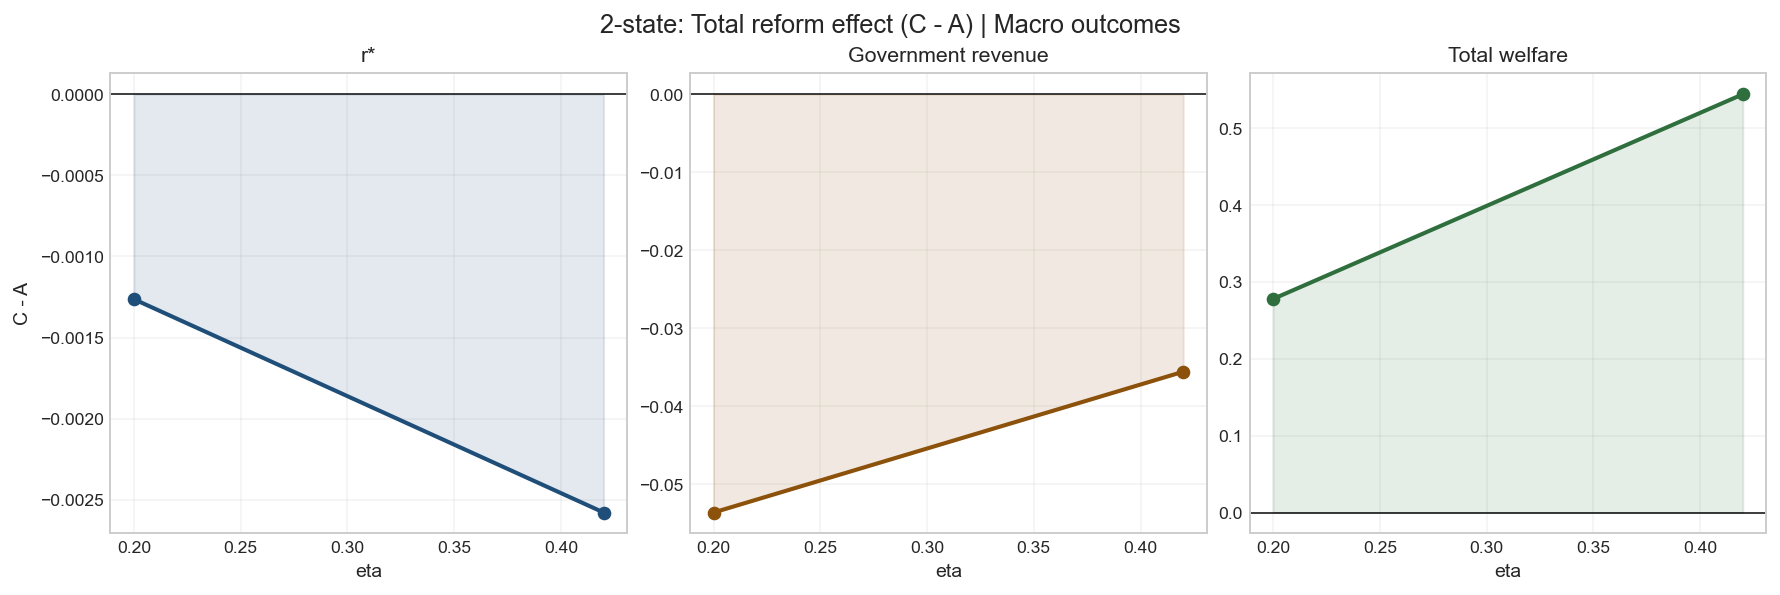

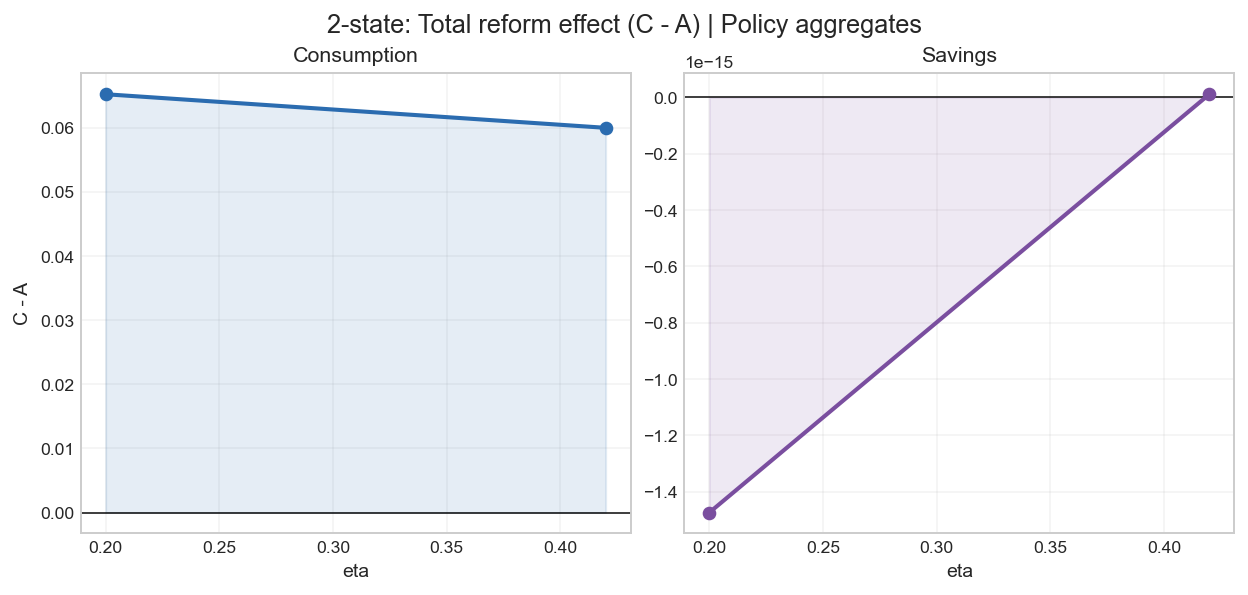

In [23]:
# C-A pure reform effect: 2-state (formal panel style)
# Metrics: consumption, savings, r*, welfare, government revenue.
# Figures are split so no panel has more than 3 charts.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 140,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

# ---------- 2-state macro C-A from reform tables ----------
rows_macro_ca_2 = []

# r* from reform2_df_main
tab2_r = long_2[
    (long_2["data_kind"] == "table")
    & (long_2["source"] == "reform2_df_main")
    & (long_2["model"].isin(["A_baseline_2024", "C_simplified_plus_lambda"]))
    & (long_2["scenario"] == "r*")
].copy()

for eta_val in sorted(tab2_r["eta"].dropna().unique()):
    sub = tab2_r[np.isclose(tab2_r["eta"], eta_val)]
    a = sub[sub["model"] == "A_baseline_2024"]["value"]
    c = sub[sub["model"] == "C_simplified_plus_lambda"]["value"]
    if len(a) and len(c):
        rows_macro_ca_2.append({
            "eta": float(eta_val),
            "metric": "r*",
            "effect_C_minus_A": float(c.iloc[0] - a.iloc[0]),
        })

# gov + welfare from reform2_df_welfare_consumption
tab2_w = long_2[
    (long_2["data_kind"] == "table")
    & (long_2["source"] == "reform2_df_welfare_consumption")
    & (long_2["model"].isin(["A_baseline_2024", "C_simplified_plus_lambda"]))
    & (long_2["scenario"].isin(["Gov (tax rev)", "Total welfare (lifetime)"]))
].copy()

metric_map_w = {
    "Gov (tax rev)": "Government revenue",
    "Total welfare (lifetime)": "Total welfare",
}

for eta_val in sorted(tab2_w["eta"].dropna().unique()):
    sub = tab2_w[np.isclose(tab2_w["eta"], eta_val)]
    for scen, metric_label in metric_map_w.items():
        a = sub[(sub["model"] == "A_baseline_2024") & (sub["scenario"] == scen)]["value"]
        c = sub[(sub["model"] == "C_simplified_plus_lambda") & (sub["scenario"] == scen)]["value"]
        if len(a) and len(c):
            rows_macro_ca_2.append({
                "eta": float(eta_val),
                "metric": metric_label,
                "effect_C_minus_A": float(c.iloc[0] - a.iloc[0]),
            })

ca_macro_2 = pd.DataFrame(rows_macro_ca_2)

# ---------- 2-state policy C-A from exported series ----------
def weighted_policy_mean_2(df_series: pd.DataFrame, metric_name: str, model_name: str, eta_val: float):
    policy = df_series[
        (df_series["source"] == "final_2state_reform_series")
        & (df_series["data_kind"] == "series")
        & (df_series["metric"] == metric_name)
        & (df_series["model"] == model_name)
        & (np.isclose(df_series["eta"], eta_val))
    ].copy()

    density = df_series[
        (df_series["source"] == "final_2state_reform_series")
        & (df_series["data_kind"] == "series")
        & (df_series["metric"] == "density")
        & (df_series["model"] == model_name)
        & (np.isclose(df_series["eta"], eta_val))
    ].copy()

    if policy.empty or density.empty:
        return np.nan

    merged = policy.merge(
        density[["model", "eta", "state", "grid_index", "value"]].rename(columns={"value": "density"}),
        on=["model", "eta", "state", "grid_index"],
        how="inner",
    )
    if merged.empty:
        return np.nan

    grid_vals = np.sort(merged["grid_value"].dropna().unique())
    da = float(np.median(np.diff(grid_vals))) if len(grid_vals) > 1 else 1.0

    num = float((merged["value"] * merged["density"]).sum() * da)
    den = float(merged["density"].sum() * da)
    return np.nan if abs(den) < 1e-14 else num / den

policy_rows_ca_2 = []
metric_titles = {"consumption": "Consumption", "savings": "Savings"}
eta_grid_2 = sorted(
    long_2[
        (long_2["source"] == "final_2state_reform_series")
        & (long_2["data_kind"] == "series")
        & (long_2["model"].isin(["A_baseline_2024", "C_simplified_plus_lambda"]))
    ]["eta"].dropna().unique()
)

for eta_val in eta_grid_2:
    for metric in ["consumption", "savings"]:
        a_val = weighted_policy_mean_2(long_2, metric, "A_baseline_2024", eta_val)
        c_val = weighted_policy_mean_2(long_2, metric, "C_simplified_plus_lambda", eta_val)
        if np.isnan(a_val) or np.isnan(c_val):
            continue
        policy_rows_ca_2.append({
            "eta": float(eta_val),
            "metric": metric_titles[metric],
            "effect_C_minus_A": float(c_val - a_val),
        })

ca_policy_2 = pd.DataFrame(policy_rows_ca_2)

if ca_macro_2.empty or ca_policy_2.empty:
    raise RuntimeError("Could not build complete C-A effects for 2-state from exported data.")

print("2-state C-A pure reform effect (sample):")
print(
    pd.concat([ca_macro_2, ca_policy_2], ignore_index=True)
    .sort_values(["metric", "eta"])
    .head(15)
    .to_string(index=False, float_format=lambda x: f"{x: .6g}")
)

# Figure A (max 3 charts): r*, gov, welfare
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.9), constrained_layout=True)
macro_order = ["r*", "Government revenue", "Total welfare"]
macro_colors = {
    "r*": "#1f4e79",
    "Government revenue": "#8c510a",
    "Total welfare": "#2f6f3e",
}

for ax, metric in zip(axes, macro_order):
    sub = ca_macro_2[ca_macro_2["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["effect_C_minus_A"], marker="o", linewidth=2.1, color=macro_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["effect_C_minus_A"], color=macro_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("C - A")
fig.suptitle("2-state: Total reform effect (C - A) | Macro outcomes", y=1.05, fontsize=13)
plt.show()

# Figure B (max 3 charts): consumption, savings
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.9), constrained_layout=True)
policy_order = ["Consumption", "Savings"]
policy_colors = {"Consumption": "#2b6cb0", "Savings": "#7a4e9f"}

for ax, metric in zip(axes, policy_order):
    sub = ca_policy_2[ca_policy_2["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["effect_C_minus_A"], marker="o", linewidth=2.1, color=policy_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["effect_C_minus_A"], color=policy_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("C - A")
fig.suptitle("2-state: Total reform effect (C - A) | Policy aggregates", y=1.05, fontsize=13)
plt.show()

4-state C-A pure reform effect (sample):
  eta             metric  effect_C_minus_A
  0.2        Consumption         0.0847132
 0.42        Consumption           0.10035
  0.2 Government revenue       -0.00452571
 0.42 Government revenue        0.00283863
  0.2            Savings       5.68425e-15
 0.42            Savings      -4.00553e-15
  0.2      Total welfare           1.69979
 0.42      Total welfare           2.21766
  0.2                 r*       -0.00376672
 0.42                 r*       -0.00447974


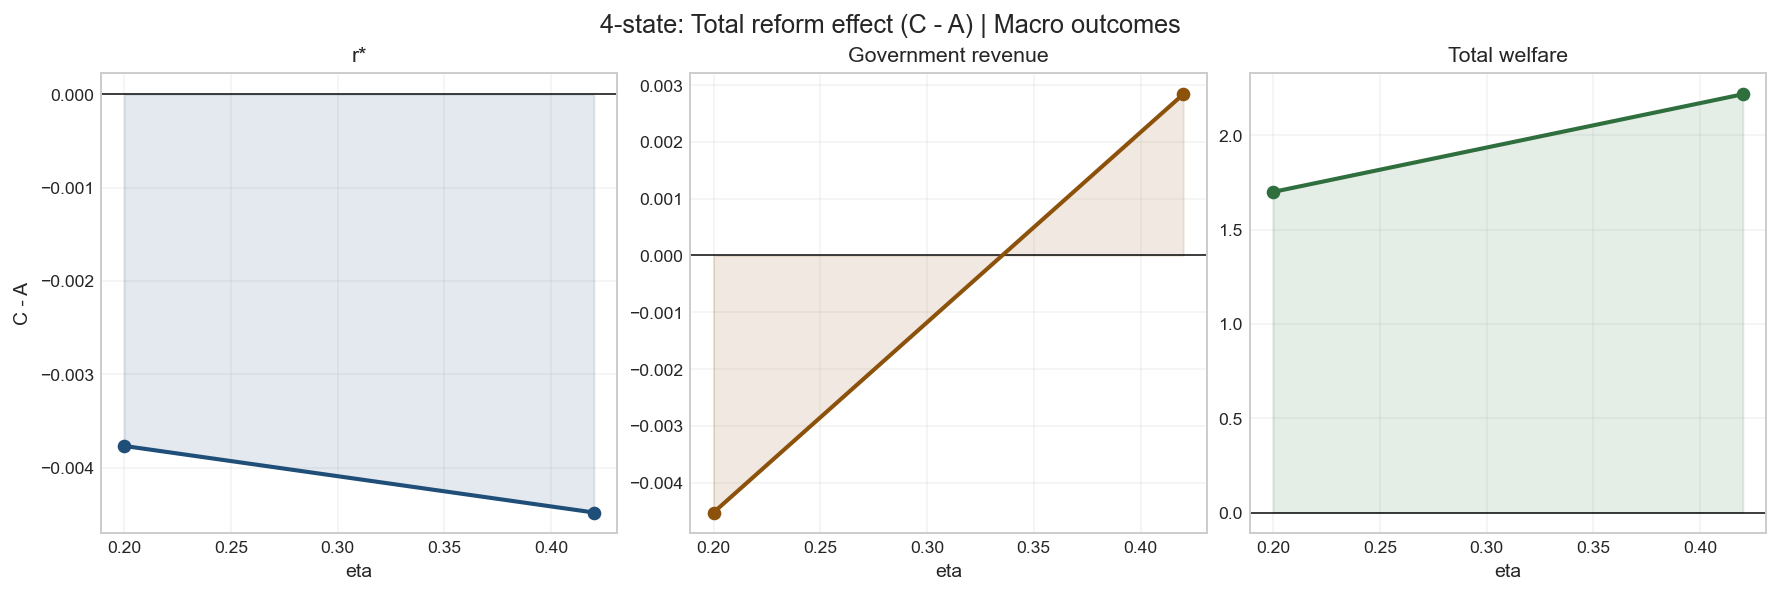

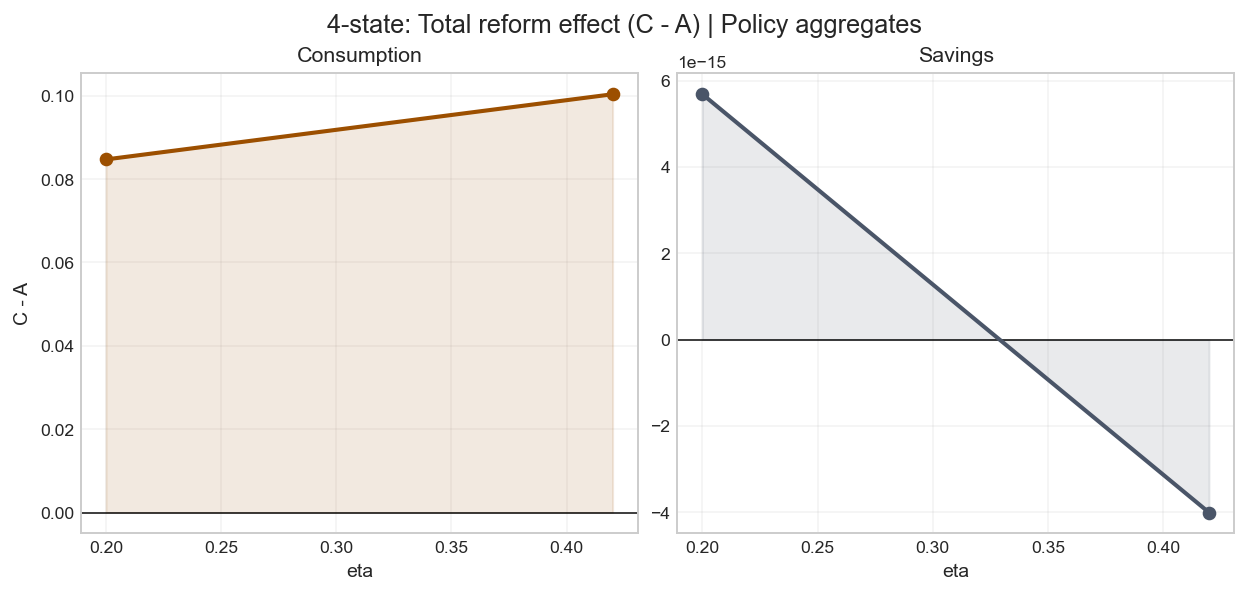

In [24]:
# C-A pure reform effect: 4-state (formal panel style)
# Metrics: consumption, savings, r*, welfare, government revenue.
# Figures are split so no panel has more than 3 charts.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 140,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

# ---------- 4-state C-A from df_3x3 table ----------
# C-A corresponds to lambda_change - baseline_2024 under find_equilibrium.
metric_map_4 = {
    "r*": "r*",
    "gov": "Government revenue",
    "total_welfare": "Total welfare",
    "avg_consumption": "Consumption",
    "avg_savings": "Savings",
}

tab4 = long_4[
    (long_4["data_kind"] == "table")
    & (long_4["source"] == "df_3x3")
    & (long_4["option"] == "find_equilibrium")
    & (long_4["model"].isin(["baseline_2024", "lambda_change"]))
    & (long_4["scenario"].isin(metric_map_4.keys()))
].copy()

rows_ca_4 = []
for eta_val in sorted(tab4["eta"].dropna().unique()):
    sub = tab4[np.isclose(tab4["eta"], eta_val)]
    for src_metric, metric_label in metric_map_4.items():
        a = sub[(sub["model"] == "baseline_2024") & (sub["scenario"] == src_metric)]["value"]
        c = sub[(sub["model"] == "lambda_change") & (sub["scenario"] == src_metric)]["value"]
        if len(a) and len(c):
            rows_ca_4.append({
                "eta": float(eta_val),
                "metric": metric_label,
                "effect_C_minus_A": float(c.iloc[0] - a.iloc[0]),
            })

ca_effects_4 = pd.DataFrame(rows_ca_4)

if ca_effects_4.empty:
    raise RuntimeError("Could not build C-A effects for 4-state from df_3x3 export rows.")

print("4-state C-A pure reform effect (sample):")
print(ca_effects_4.sort_values(["metric", "eta"]).to_string(index=False, float_format=lambda x: f"{x: .6g}"))

# Figure A (max 3 charts): r*, gov, welfare
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.9), constrained_layout=True)
macro_order = ["r*", "Government revenue", "Total welfare"]
macro_colors = {
    "r*": "#1f4e79",
    "Government revenue": "#8c510a",
    "Total welfare": "#2f6f3e",
}

for ax, metric in zip(axes, macro_order):
    sub = ca_effects_4[ca_effects_4["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["effect_C_minus_A"], marker="o", linewidth=2.1, color=macro_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["effect_C_minus_A"], color=macro_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("C - A")
fig.suptitle("4-state: Total reform effect (C - A) | Macro outcomes", y=1.05, fontsize=13)
plt.show()

# Figure B (max 3 charts): consumption, savings
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.9), constrained_layout=True)
policy_order = ["Consumption", "Savings"]
policy_colors = {"Consumption": "#9c4f00", "Savings": "#4a5568"}

for ax, metric in zip(axes, policy_order):
    sub = ca_effects_4[ca_effects_4["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["effect_C_minus_A"], marker="o", linewidth=2.1, color=policy_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["effect_C_minus_A"], color=policy_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("C - A")
fig.suptitle("4-state: Total reform effect (C - A) | Policy aggregates", y=1.05, fontsize=13)
plt.show()

(C-A) 4-state minus (C-A) 2-state: sample
  eta             metric  effect_C_minus_A_4  effect_C_minus_A_2  gap_4minus2
  0.2                 r*         -0.00376672         -0.00126358  -0.00250314
 0.42                 r*         -0.00447974         -0.00257843  -0.00190131
  0.2 Government revenue         -0.00452571             -0.0536    0.0490743
 0.42 Government revenue          0.00283863            -0.03556    0.0383986
  0.2      Total welfare             1.69979            0.277976      1.42182
 0.42      Total welfare             2.21766            0.544365       1.6733
  0.2        Consumption           0.0847132           0.0652402     0.019473
 0.42        Consumption             0.10035           0.0600038    0.0403466
  0.2            Savings         5.68425e-15        -1.47371e-15  7.15796e-15
 0.42            Savings        -4.00553e-15         1.13362e-17 -4.01687e-15


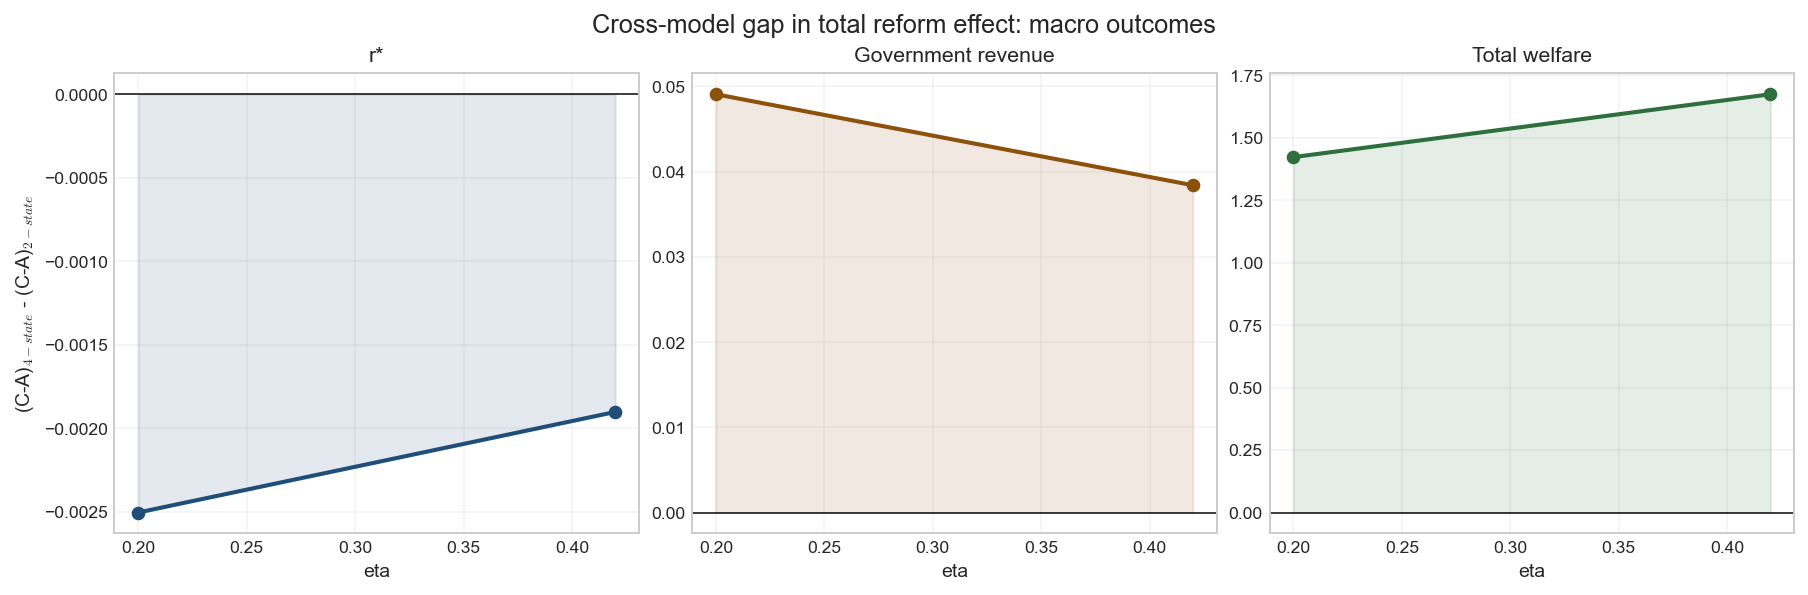

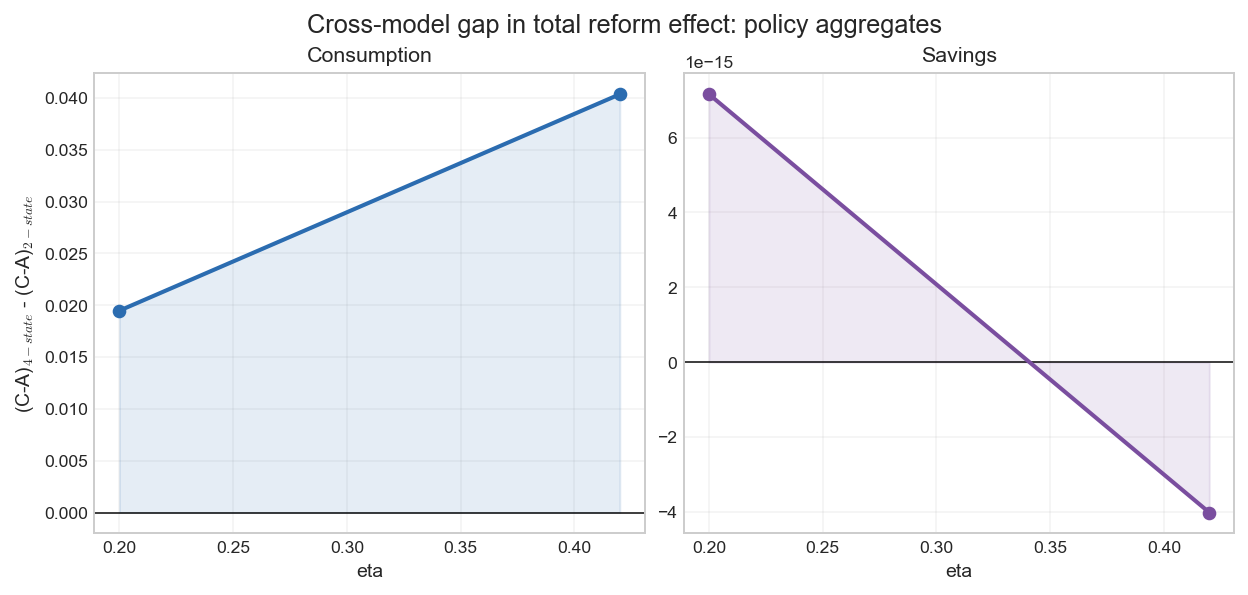

In [25]:
# Final cross-model comparison: (C - A) in 4-state minus (C - A) in 2-state
# Variables: r*, Government revenue, Total welfare, Consumption, Savings
# Layout kept in two figures so no panel has more than 3 charts.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 140,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

# 1) Build the cross-model gap table from the already computed C-A tables.
# 4-state source: ca_effects_4
# 2-state source: ca_macro_2 + ca_policy_2

ca_2_macro = ca_macro_2.rename(columns={"effect_C_minus_A": "effect_C_minus_A_2"}).copy()
ca_2_policy = ca_policy_2.rename(columns={"effect_C_minus_A": "effect_C_minus_A_2"}).copy()
ca_4 = ca_effects_4.rename(columns={"effect_C_minus_A": "effect_C_minus_A_4"}).copy()

# Standardize metric labels.
ca_2 = pd.concat([ca_2_macro, ca_2_policy], ignore_index=True)
ca_2 = ca_2[["eta", "metric", "effect_C_minus_A_2"]].copy()
ca_4 = ca_4[["eta", "metric", "effect_C_minus_A_4"]].copy()

ca_gap_compare = ca_4.merge(ca_2, on=["eta", "metric"], how="inner")
ca_gap_compare["gap_4minus2"] = ca_gap_compare["effect_C_minus_A_4"] - ca_gap_compare["effect_C_minus_A_2"]

metric_order = ["r*", "Government revenue", "Total welfare", "Consumption", "Savings"]
ca_gap_compare["metric"] = pd.Categorical(ca_gap_compare["metric"], categories=metric_order, ordered=True)
ca_gap_compare = ca_gap_compare.sort_values(["metric", "eta"]).reset_index(drop=True)

print("(C-A) 4-state minus (C-A) 2-state: sample")
print(ca_gap_compare.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

# 2) Figure A: macro outcomes (3 panels)
fig, axes = plt.subplots(1, 3, figsize=(12.8, 3.9), constrained_layout=True)
macro_order = ["r*", "Government revenue", "Total welfare"]
macro_colors = {
    "r*": "#1f4e79",
    "Government revenue": "#8c510a",
    "Total welfare": "#2f6f3e",
}

for ax, metric in zip(axes, macro_order):
    sub = ca_gap_compare[ca_gap_compare["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["gap_4minus2"], marker="o", linewidth=2.1, color=macro_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["gap_4minus2"], color=macro_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("(C-A)$_{4-state}$ - (C-A)$_{2-state}$")
fig.suptitle("Cross-model gap in total reform effect: macro outcomes", y=1.05, fontsize=13)
plt.show()

# 3) Figure B: policy aggregates (2 panels)
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.9), constrained_layout=True)
policy_order = ["Consumption", "Savings"]
policy_colors = {"Consumption": "#2b6cb0", "Savings": "#7a4e9f"}

for ax, metric in zip(axes, policy_order):
    sub = ca_gap_compare[ca_gap_compare["metric"] == metric].sort_values("eta")
    ax.axhline(0, color="black", linewidth=1.0, alpha=0.75)
    ax.plot(sub["eta"], sub["gap_4minus2"], marker="o", linewidth=2.1, color=policy_colors[metric])
    ax.fill_between(sub["eta"], 0, sub["gap_4minus2"], color=policy_colors[metric], alpha=0.12)
    ax.set_title(metric)
    ax.set_xlabel("eta")
    ax.grid(alpha=0.25)

axes[0].set_ylabel("(C-A)$_{4-state}$ - (C-A)$_{2-state}$")
fig.suptitle("Cross-model gap in total reform effect: policy aggregates", y=1.05, fontsize=13)
plt.show()

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.family": "serif",
    "figure.dpi": 140,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "legend.frameon": False,
})


def find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / "1. data").exists() and (p / "2. code").exists():
            return p
    return start


project_root = find_project_root(Path.cwd())
output_dir = project_root / "1. data" / "output_data"

csv_2 = output_dir / "reform2_ABC_r_gov_welfare.csv"
csv_4 = output_dir / "reform4_ABC_rstar_exog_rebate_feedback.csv"

if not csv_2.exists():
    raise FileNotFoundError(f"Missing file: {csv_2}")
if not csv_4.exists():
    raise FileNotFoundError(f"Missing file: {csv_4}")

df_2_abc = pd.read_csv(csv_2)
df_4_abc = pd.read_csv(csv_4)

# Standardize names for plotting.
df_2_abc = df_2_abc.rename(columns={"eta_base": "eta", "total_welfare_lifetime": "welfare"}).copy()
df_4_abc = df_4_abc.rename(columns={"total_welfare": "welfare"}).copy()

for df in (df_2_abc, df_4_abc):
    df["eta"] = pd.to_numeric(df["eta"], errors="coerce")
    df["r_star"] = pd.to_numeric(df["r_star"], errors="coerce")
    df["gov"] = pd.to_numeric(df["gov"], errors="coerce")
    df["welfare"] = pd.to_numeric(df["welfare"], errors="coerce")

case_map = {
    "2-state": {
        "BA": {"A": "A_baseline_2024", "B": "B_simplified_tax"},
        "CA": {"A": "A_baseline_2024", "C": "C_simplified_plus_lambda"},
    },
    "4-state": {
        "BA": {"A": "baseline_2024", "B": "tax_reform"},
        "CA": {"A": "baseline_2024", "C": "lambda_change"},
    },
}


def build_delta_table(df: pd.DataFrame, approach: str, case_a: str, case_b: str) -> pd.DataFrame:
    sub = df[df["approach"] == approach].copy()
    rows = []
    for eta_val in sorted(sub["eta"].dropna().unique()):
        a_row = sub[(np.isclose(sub["eta"], eta_val)) & (sub["Case"] == case_a)]
        b_row = sub[(np.isclose(sub["eta"], eta_val)) & (sub["Case"] == case_b)]
        if a_row.empty or b_row.empty:
            continue
        a = a_row.iloc[0]
        b = b_row.iloc[0]
        rows.append({
            "eta": float(eta_val),
            "r_star": float(b["r_star"] - a["r_star"]),
            "gov": float(b["gov"] - a["gov"]),
            "welfare": float(b["welfare"] - a["welfare"]),
        })
    return pd.DataFrame(rows).sort_values("eta").reset_index(drop=True)


def plot_delta_comparison(delta_2: pd.DataFrame, delta_4: pd.DataFrame, title: str):
    fig, axes = plt.subplots(1, 3, figsize=(13.4, 4.5), constrained_layout=True)
    metric_specs = [
        ("r_star", r"$\Delta\, r^*$"),
        ("gov",    r"$\Delta$ government revenue"),
        ("welfare",r"$\Delta$ government welfare"),
    ]
    palette = {"2-state": "#b85c1e", "4-state": "#1f4e79"}

    lines = {}
    for ax, (metric, ylabel) in zip(axes, metric_specs):
        vals_2 = delta_2[metric].dropna()
        vals_4 = delta_4[metric].dropna()
        all_vals = pd.concat([vals_2, vals_4])

        lo, hi = all_vals.min(), all_vals.max()
        span = hi - lo if hi != lo else abs(hi) * 0.2 or 0.01
        pad  = span * 0.25
        ymin = lo - pad
        ymax = hi + pad
        if lo > 0:
            ymin = min(ymin, -pad)
        if hi < 0:
            ymax = max(ymax,  pad)

        ax.set_ylim(ymin, ymax)
        ax.axhline(0, color="black", linewidth=0.9, alpha=0.6, zorder=1)
        l2, = ax.plot(delta_2["eta"], vals_2,
                marker="o", linewidth=2.2, markersize=6,
                color=palette["2-state"], label="2-state", zorder=3)
        l4, = ax.plot(delta_4["eta"], vals_4,
                marker="o", linewidth=2.2, markersize=6,
                color=palette["4-state"], label="4-state", zorder=3)
        lines["2-state"] = l2
        lines["4-state"] = l4

        ax.set_title(ylabel, pad=4, fontsize=11)
        ax.set_xlabel(r"$\eta$")
        ax.grid(alpha=0.25)
        ax.set_xticks(sorted(set(delta_2["eta"]).union(set(delta_4["eta"]))))
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.3f}"))

    axes[0].set_ylabel("Difference")

    # Suptitle at the very top
    fig.suptitle(title, fontsize=13, y=1.15)

    # Legend anchored just below the suptitle, above the subplots
    fig.legend(
        handles=list(lines.values()),
        labels=list(lines.keys()),
        loc="upper center",
        ncol=2,
        bbox_to_anchor=(0.5, 1.1),   # sits between suptitle and subplot titles
        frameon=False,
        fontsize=10,
    )

    plt.show()

print("Loaded:")
print(f"2-state: {csv_2}")
print(f"4-state: {csv_4}")
print("2-state columns:", list(df_2_abc.columns))
print("4-state columns:", list(df_4_abc.columns))

Loaded:
2-state: c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\reform2_ABC_r_gov_welfare.csv
4-state: c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\reform4_ABC_rstar_exog_rebate_feedback.csv
2-state columns: ['Case', 'eta', 'approach', 'r_star', 'gov', 'welfare', 'transfer_per_capita']
4-state columns: ['approach', 'option', 'Case', 'eta', 'r_star', 'gov', 'welfare']


2-state B-A (lump-sum rebate)
  eta        r_star     gov      welfare
  0.2 -0.0014633178  -0.056  -0.01638246
 0.42  -0.002685242 -0.0406 -0.025205084

4-state B-A (lump-sum rebate)
  eta        r_star           gov     welfare
  0.2 -0.0053583984  -0.010568953   0.7073074
 0.42 -0.0055276489 -0.0098257825  0.67436614


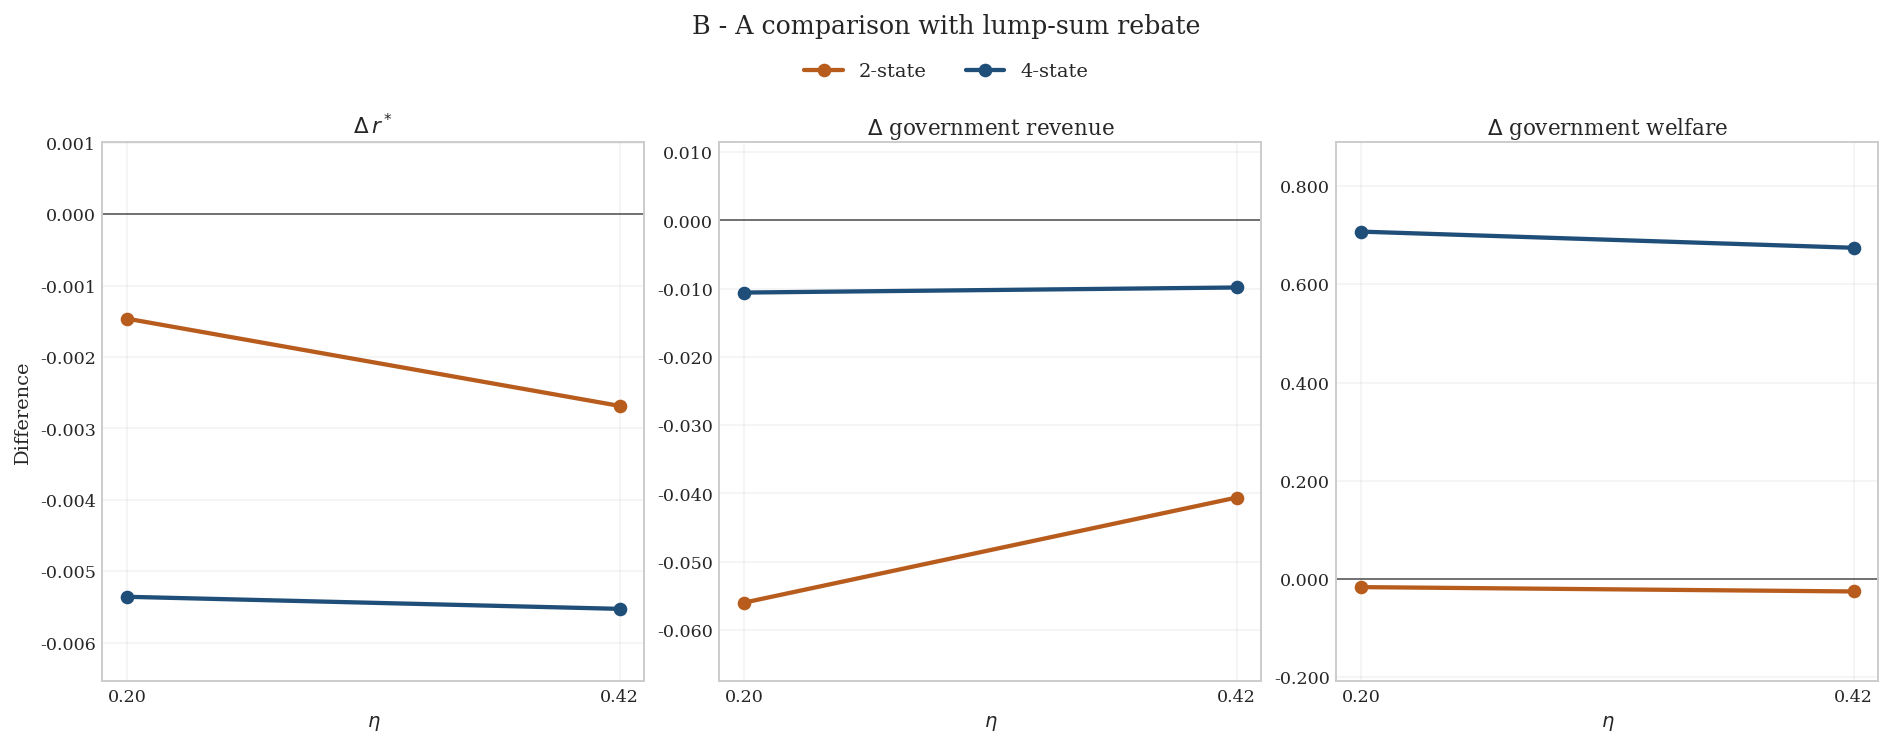

In [22]:
# B - A comparison using lump-sum rebate
case_2 = case_map["2-state"]["BA"]
case_4 = case_map["4-state"]["BA"]

delta_2 = build_delta_table(df_2_abc, "lump_sum_rebate", case_2["A"], case_2["B"])
delta_4 = build_delta_table(df_4_abc, "lump_sum_rebate", case_4["A"], case_4["B"])

if delta_2.empty or delta_4.empty:
    raise RuntimeError("Missing B-A rebate rows for one of the datasets.")

print("2-state B-A (lump-sum rebate)")
print(delta_2.to_string(index=False, float_format=lambda x: f"{x: .8g}"))
print()
print("4-state B-A (lump-sum rebate)")
print(delta_4.to_string(index=False, float_format=lambda x: f"{x: .8g}"))

plot_delta_comparison(delta_2, delta_4, "B - A comparison with lump-sum rebate")

2-state B-A (gov feedback)
  eta        r_star          gov     welfare
  0.2  -0.001365585 -0.063661824 -0.55414325
 0.42 -0.0025666808 -0.044516688   -0.328614

4-state B-A (gov feedback)
  eta        r_star          gov     welfare
  0.2 -0.0053385925 -0.011211263  0.67031677
 0.42 -0.0055132446 -0.010379177  0.64330183


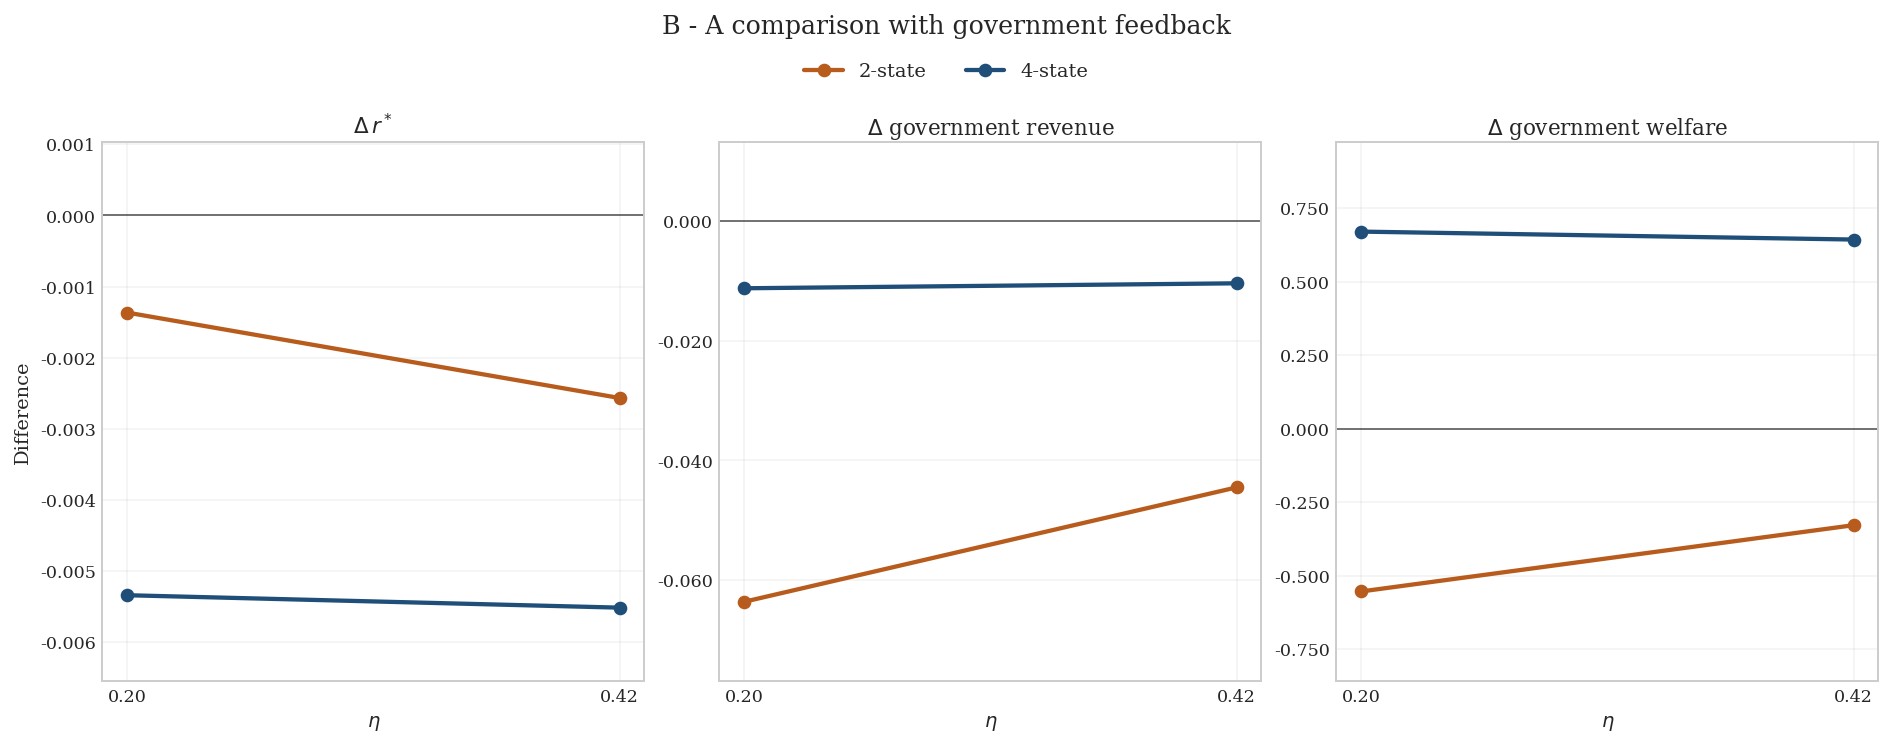

In [23]:
# B - A comparison using government feedback
case_2 = case_map["2-state"]["BA"]
case_4 = case_map["4-state"]["BA"]

delta_2 = build_delta_table(df_2_abc, "gov_feedback", case_2["A"], case_2["B"])
delta_4 = build_delta_table(df_4_abc, "gov_feedback", case_4["A"], case_4["B"])

if delta_2.empty or delta_4.empty:
    raise RuntimeError("Missing B-A gov-feedback rows for one of the datasets.")

print("2-state B-A (gov feedback)")
print(delta_2.to_string(index=False, float_format=lambda x: f"{x: .8g}"))
print()
print("4-state B-A (gov feedback)")
print(delta_4.to_string(index=False, float_format=lambda x: f"{x: .8g}"))

plot_delta_comparison(delta_2, delta_4, "B - A comparison with government feedback")

2-state C-A (lump-sum rebate)
  eta      r_star      gov    welfare
  0.2 -0.00126358  -0.0536  0.2264065
 0.42 -0.00257843 -0.03556  0.4897027

4-state C-A (lump-sum rebate)
  eta        r_star           gov    welfare
  0.2 -0.0037667236 -0.0045257081  1.6697385
 0.42 -0.0046994019 -0.0025563079  1.8073725


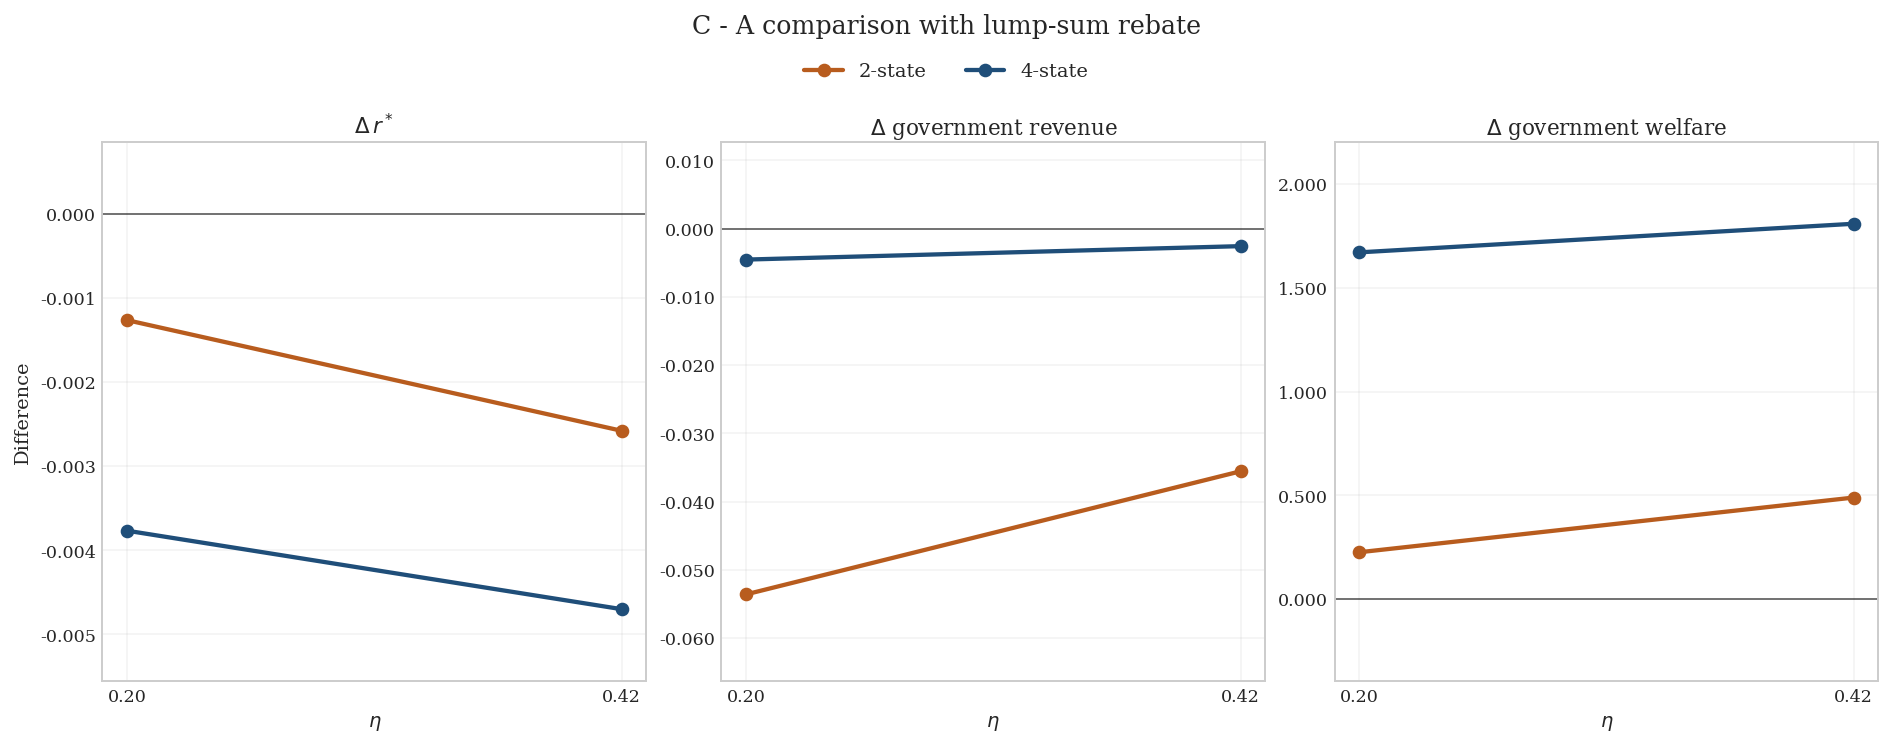

In [24]:
# C - A comparison using lump-sum rebate
case_2 = case_map["2-state"]["CA"]
case_4 = case_map["4-state"]["CA"]

delta_2 = build_delta_table(df_2_abc, "lump_sum_rebate", case_2["A"], case_2["C"])
delta_4 = build_delta_table(df_4_abc, "lump_sum_rebate", case_4["A"], case_4["C"])

if delta_2.empty or delta_4.empty:
    raise RuntimeError("Missing C-A rebate rows for one of the datasets.")

print("2-state C-A (lump-sum rebate)")
print(delta_2.to_string(index=False, float_format=lambda x: f"{x: .8g}"))
print()
print("4-state C-A (lump-sum rebate)")
print(delta_4.to_string(index=False, float_format=lambda x: f"{x: .8g}"))

plot_delta_comparison(delta_2, delta_4, "C - A comparison with lump-sum rebate")

2-state C-A (gov feedback)
  eta        r_star          gov     welfare
  0.2   -0.00118454 -0.061010364 -0.27298358
 0.42 -0.0024919127 -0.039092544  0.24872546

4-state C-A (gov feedback)
  eta        r_star           gov    welfare
  0.2  -0.003784729  -0.004815696  1.7095621
 0.42 -0.0047606201 -0.0027103814  1.8628571


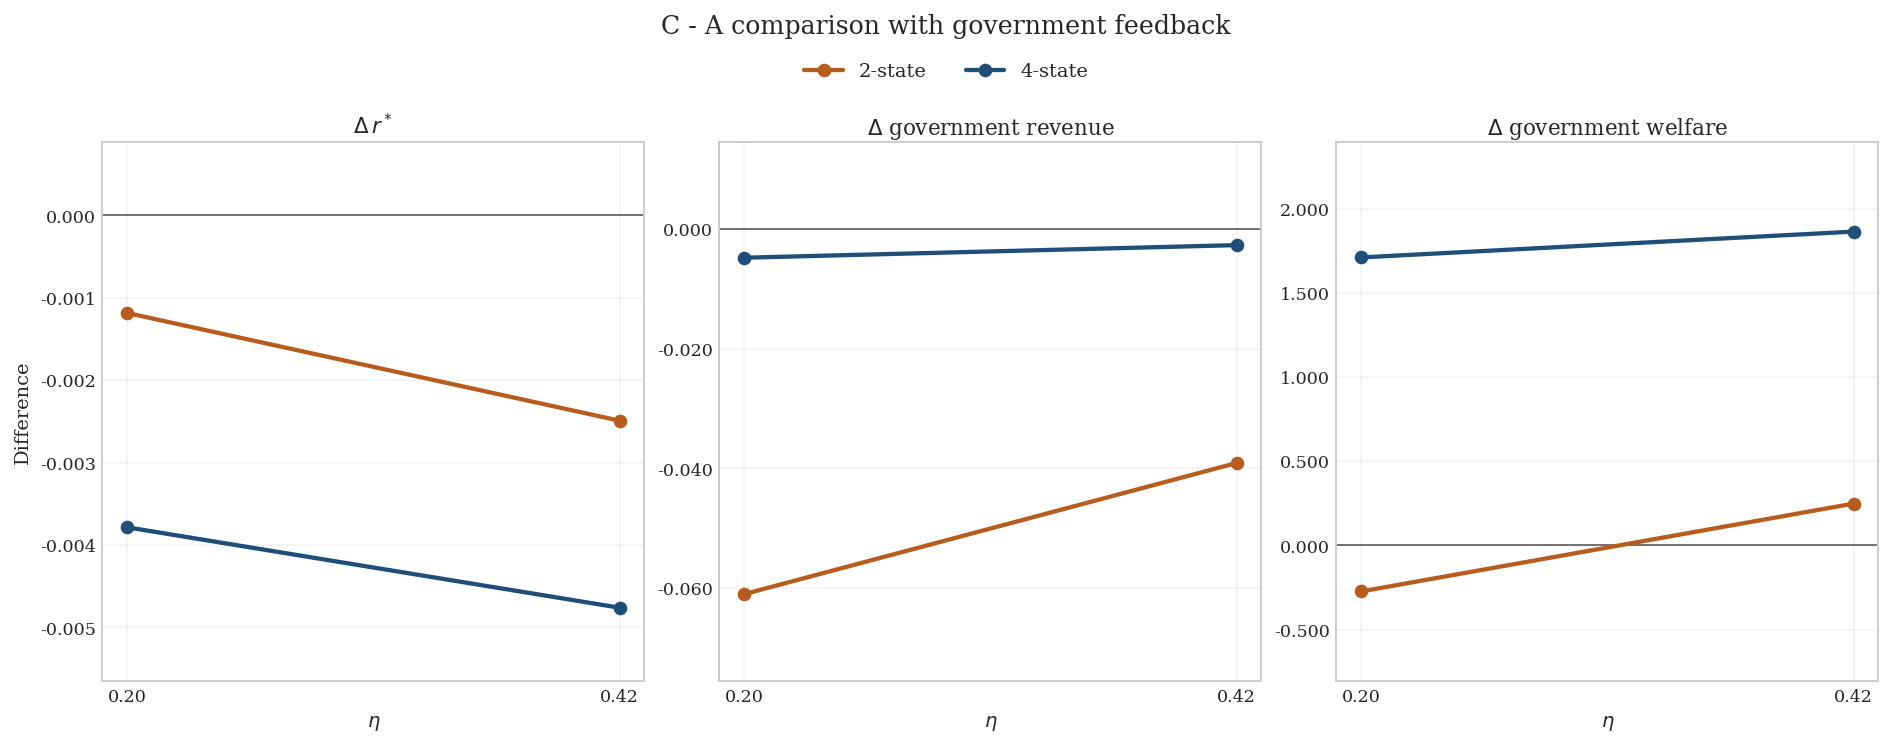

In [25]:
# C - A comparison using government feedback
case_2 = case_map["2-state"]["CA"]
case_4 = case_map["4-state"]["CA"]

delta_2 = build_delta_table(df_2_abc, "gov_feedback", case_2["A"], case_2["C"])
delta_4 = build_delta_table(df_4_abc, "gov_feedback", case_4["A"], case_4["C"])

if delta_2.empty or delta_4.empty:
    raise RuntimeError("Missing C-A gov-feedback rows for one of the datasets.")

print("2-state C-A (gov feedback)")
print(delta_2.to_string(index=False, float_format=lambda x: f"{x: .8g}"))
print()
print("4-state C-A (gov feedback)")
print(delta_4.to_string(index=False, float_format=lambda x: f"{x: .8g}"))

plot_delta_comparison(delta_2, delta_4, "C - A comparison with government feedback")